# Attrition client : qui contacter, et est-ce rentable ?

Analyse du jeu public Telco Customer Churn (IBM) : 7 043 clients d'un opérateur télécom, 21 colonnes.

**Question métier.** L'opérateur veut proposer une offre de rétention aux clients susceptibles de partir. L'offre a un coût, et l'équipe ne peut pas appeler tout le monde. Je cherche à répondre à trois questions : qui risque de partir, lesquels de ces clients valent la peine d'être contactés, et quel profit attendre de la campagne.

## Résultats principaux

| | |
|---|---|
| Clients partis | 26,5 % des clients, 30,5 % de la facturation mensuelle |
| Modèle retenu | Régression logistique avec pénalité L1 ; le gradient boosting réglé ne fait pas mieux |
| PR-AUC (test) | 0,654 [IC 95 % : 0,601 à 0,704], contre 0,265 pour un tirage au hasard |
| ROC-AUC (test) | 0,846 [IC 95 % : 0,824 à 0,867] |
| Calibration (test) | Brier 0,136 ; écart moyen de 1,2 point entre probabilité prédite et fréquence observée |
| Règle de contact | contacter si probabilité × taux de rétention × valeur du client ≥ coût de l'offre |
| Profit attendu (test) | 10 732 $ pour 363 contacts sur 1 409 clients [IC 95 % : 7 742 $ à 13 622 $] |
| Point de bascule | la campagne perd de l'argent si l'offre retient moins de 20 % des partants contactés |

Ce que j'en retiens pour le métier :

1. Trois facteurs dominent : le type de contrat, l'ancienneté et l'accès internet par fibre. Les clients arrivés depuis six mois ou moins (21 % de la base) partent à 53 %.
2. La fibre pose un problème à part entière : à contrat égal, ses clients partent nettement plus que ceux de l'ADSL (55 % contre 32 % sans engagement), alors qu'ils paient 25 $ de plus par mois.
3. Le bon critère de contact n'est pas le risque seul, mais le risque multiplié par la valeur du client. Avec l'offre étudiée, un client facturé moins de 33,33 $ par mois ne justifie jamais un contact, même s'il est certain de partir.
4. Tout repose sur le taux de rétention de l'offre, qui est une hypothèse. Un test A/B de 286 clients par groupe suffit à détecter un effet proche du seuil de rentabilité.

## Plan

1. Cadrage métier et hypothèses économiques
2. Données et qualité
3. Exploration : qui part ?
4. Protocole et choix des variables
5. Comparaison de modèles
6. Réglage et choix du modèle
7. Déséquilibre des classes
8. Calibration
9. Règle de décision
10. Évaluation finale sur le jeu de test
11. Segmentation risque × valeur
12. Interprétation
13. Analyse des erreurs
14. Robustesse
15. Plan de test A/B
16. Conclusions

Les montants sont exprimés en dollars, comme dans le jeu de données.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

RANDOM_STATE = 42
RACINE = Path("..")
FIG = RACINE / "figures"
RES = RACINE / "resultats"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

BLEU, ORANGE, VERT, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": "#0b0b0b",
    "legend.frameon": False,
})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)


def pct(x, d=1):
    """Pourcentage au format français : 0.2654 -> '26,5 %'."""
    return f"{100 * x:.{d}f} %".replace(".", ",")


def usd(x, d=0):
    """Montant au format français : 11640.5 -> '11 640 $'."""
    return f"{x:,.{d}f} $".replace(",", " ").replace(".", ",")


def sauver(fig, nom):
    fig.savefig(FIG / f"{nom}.png", bbox_inches="tight", dpi=130)


R = {}  # chiffres clés, repris dans le texte et le README
print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 3.0.5 | numpy 2.5.3


## 1. Cadrage métier

L'action étudiée est une offre de rétention (geste commercial et appel d'un conseiller) proposée aux clients jugés à risque. Pour savoir si elle est rentable, il faut chiffrer quatre paramètres. Aucun ne figure dans les données : ce sont des hypothèses de travail, posées ici pour être discutées, puis testées en section 10.

| Paramètre | Valeur retenue | Sens |
|---|---|---|
| Coût d'un contact | 60 $ | geste commercial et temps du conseiller |
| Taux de rétention | 30 % | part des futurs partants contactés que l'offre fait rester |
| Marge | 50 % de la facture | part de la facture mensuelle qui est du profit |
| Horizon | 12 mois | durée de facturation gagnée quand un départ est évité |

La valeur d'un client conservé dépend donc de sa facture : marge × horizon × facture mensuelle, soit 6 fois la facture. Contacter un client dont la probabilité de départ est p rapporte en moyenne p × 30 % × sa valeur, et coûte 60 $ dans tous les cas. Je compte ce coût pour chaque client contacté, même s'il n'utilise pas l'offre : c'est une hypothèse prudente.

In [2]:
COUT_OFFRE = 60        # $ par client contacté : geste commercial + temps du conseiller
TAUX_RETENTION = 0.30  # part des futurs partants contactés que l'offre retient
MARGE = 0.50           # part de la facture mensuelle qui est de la marge
HORIZON = 12           # mois de facturation conservés quand un départ est évité

facture_min = COUT_OFFRE / (TAUX_RETENTION * MARGE * HORIZON)
print(f"Valeur d'un client conservé : {MARGE * HORIZON:.0f} × sa facture mensuelle")
print(f"Gain espéré d'un contact : p × {pct(TAUX_RETENTION, 0)} × valeur − {COUT_OFFRE} $")
print(f"Facture minimale pour qu'un contact soit rentable, même avec p = 1 : {usd(facture_min, 2)}")

R.update(cout_offre=COUT_OFFRE, taux_retention=TAUX_RETENTION, marge=MARGE,
         horizon=HORIZON, facture_min=facture_min, multiple_valeur=MARGE * HORIZON)

Valeur d'un client conservé : 6 × sa facture mensuelle
Gain espéré d'un contact : p × 30 % × valeur − 60 $
Facture minimale pour qu'un contact soit rentable, même avec p = 1 : 33,33 $


Conséquence immédiate : un client qui paie moins de 33,33 $ par mois ne vaut jamais le coût de l'offre, même s'il est certain de partir. Pour ces clients, il faudrait une action moins chère.

## 2. Données et qualité

Avant de modéliser, je vérifie les types, les valeurs manquantes et la cohérence des montants.

In [3]:
df_brut = pd.read_csv(RACINE / "data" / "telco_customer_churn.csv")
print(f"{len(df_brut)} clients, {df_brut.shape[1]} colonnes")

pd.DataFrame({
    "type": df_brut.dtypes.astype(str),
    "manquants": df_brut.isna().sum(),
    "modalités": df_brut.nunique(),
})

7043 clients, 21 colonnes


,type,manquants,modalités
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


Aucune valeur manquante n'est déclarée, mais `TotalCharges` est lue comme du texte alors que c'est un montant. Je cherche les valeurs qui ne se convertissent pas en nombre.

In [4]:
total_num = pd.to_numeric(df_brut["TotalCharges"], errors="coerce")
vides = total_num.isna()

print(f"TotalCharges non convertibles en nombre : {vides.sum()}")
print(f"Ancienneté de ces clients               : {sorted(df_brut.loc[vides, 'tenure'].unique())}")
print(f"Clients d'ancienneté 0 dans le fichier  : {(df_brut['tenure'] == 0).sum()}")
print(f"Doublons sur customerID                 : {df_brut['customerID'].duplicated().sum()}")
print(f"Montants négatifs                       : {(df_brut['MonthlyCharges'] < 0).sum()}")

R.update(n_clients=len(df_brut), n_colonnes=df_brut.shape[1], n_total_vide=int(vides.sum()))

TotalCharges non convertibles en nombre : 11
Ancienneté de ces clients               : [np.int64(0)]
Clients d'ancienneté 0 dans le fichier  : 11
Doublons sur customerID                 : 0
Montants négatifs                       : 0


Les 11 valeurs vides correspondent exactement aux 11 clients d'ancienneté 0 : ils viennent de souscrire et n'ont pas encore été facturés. Je les remplace par 0, qui est la vraie valeur. Supprimer ces lignes aurait retiré des nouveaux clients, le groupe le plus à risque ; les remplacer par la médiane leur aurait inventé un historique de facturation.

Les modalités « No internet service » et « No phone service » répètent une information déjà présente dans `InternetService` et `PhoneService`. Je les ramène à « No » pour éviter des indicatrices redondantes dans le modèle.

In [5]:
OPTIONS_INTERNET = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                    "TechSupport", "StreamingTV", "StreamingMovies"]

df = df_brut.copy()
df["TotalCharges"] = total_num.fillna(0.0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# « No internet service » répète l'information de InternetService == "No" ;
# « No phone service » répète PhoneService == "No". On les ramène à "No".
for col in OPTIONS_INTERNET:
    df[col] = df[col].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

print({col: sorted(df[col].unique()) for col in ["OnlineSecurity", "MultipleLines"]})

{'OnlineSecurity': ['No', 'Yes'], 'MultipleLines': ['No', 'Yes']}


### 2.1 Ce que contient la facture

Je vérifie si la facture mensuelle apporte une information propre, ou si elle découle des services souscrits.

In [6]:
from sklearn.linear_model import LinearRegression

services = pd.get_dummies(
    df[OPTIONS_INTERNET + ["MultipleLines", "PhoneService", "InternetService"]],
    drop_first=True, dtype=float,
)
grille = LinearRegression().fit(services, df["MonthlyCharges"])
r2_grille = grille.score(services, df["MonthlyCharges"])

print(f"R² de MonthlyCharges expliqué par les seuls services souscrits : {r2_grille:.4f}\n")
print("Prix mensuel de chaque service (référence : ADSL, sans option) :")
print(pd.Series(grille.coef_, index=services.columns).round(1).to_string())
print(f"Constante : {grille.intercept_:.1f} $")

prix = pd.Series(grille.coef_, index=services.columns)
R.update(r2_grille=r2_grille, surcout_fibre=float(prix["InternetService_Fiber optic"]),
         prix_base=float(grille.intercept_), prix_secu=float(prix["OnlineSecurity_Yes"]),
         prix_tv=float(prix["StreamingTV_Yes"]), prix_tel=float(prix["PhoneService_Yes"]))

R² de MonthlyCharges expliqué par les seuls services souscrits : 0.9988

Prix mensuel de chaque service (référence : ADSL, sans option) :
OnlineSecurity_Yes              5.0
OnlineBackup_Yes                5.0
DeviceProtection_Yes            5.0
TechSupport_Yes                 5.0
StreamingTV_Yes                10.0
StreamingMovies_Yes            10.0
MultipleLines_Yes               5.0
PhoneService_Yes               20.1
InternetService_Fiber optic    25.0
InternetService_No            -25.0
Constante : 25.0 $


La facture est presque entièrement déterminée par une grille tarifaire (R² = 0,9988) : 25 $ pour l'ADSL seul, 25 $ de plus pour la fibre, 5 $ par option de sécurité, de sauvegarde, de protection ou d'assistance, 10 $ par option TV ou films, 20 $ pour la téléphonie. J'en tire deux conséquences :

- `MonthlyCharges` n'apporte presque rien de plus que la liste des services. Dans un modèle linéaire, garder les deux rendrait les coefficients impossibles à interpréter. Je teste son retrait en section 4.
- À options égales, la fibre coûte 25 $ de plus par mois que l'ADSL. Ce point compte pour lire la suite.

## 3. Exploration : qui part ?

### 3.1 Volume et poids financier

In [7]:
taux = df["Churn"].mean()
ca = df["MonthlyCharges"].sum()
ca_partants = df.loc[df["Churn"] == 1, "MonthlyCharges"].sum()
facture_partants = df.loc[df["Churn"] == 1, "MonthlyCharges"].mean()
facture_restants = df.loc[df["Churn"] == 0, "MonthlyCharges"].mean()

print(f"Taux de départ                    : {pct(taux)} ({df['Churn'].sum()} clients)")
print(f"Facturation mensuelle des partants : {usd(ca_partants)} sur {usd(ca)}, soit {pct(ca_partants / ca)}")
print(f"Facture moyenne des partants       : {usd(facture_partants, 2)}")
print(f"Facture moyenne des autres         : {usd(facture_restants, 2)}")

R.update(taux_churn=taux, n_partants=int(df["Churn"].sum()), ca_mensuel=ca,
         ca_partants=ca_partants, part_ca_partants=ca_partants / ca,
         facture_moy_partants=facture_partants, facture_moy_restants=facture_restants)

Taux de départ                    : 26,5 % (1869 clients)
Facturation mensuelle des partants : 139 131 $ sur 456 117 $, soit 30,5 %
Facture moyenne des partants       : 74,44 $
Facture moyenne des autres         : 61,27 $


26,5 % des clients sont partis, et ils représentaient 30,5 % de la facturation mensuelle. Les partants payaient en moyenne plus cher (74,44 $ contre 61,27 $) : chaque départ coûte plus que la moyenne ne le laisse penser.

IBM définit la cible comme un départ au cours du dernier mois. Un taux de 26,5 % sur un seul mois serait très élevé pour un opérateur réel : le jeu est en partie synthétique. Je lis donc les niveaux absolus avec prudence, mais les écarts entre groupes de clients restent informatifs.

### 3.2 Contrat, accès internet, paiement

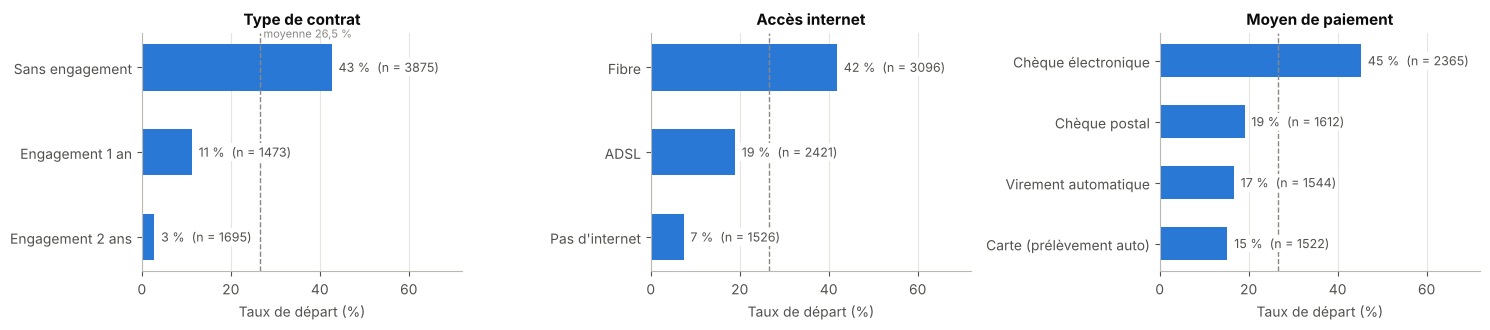

In [8]:
LIBELLES = {
    "Contract": {"Month-to-month": "Sans engagement", "One year": "Engagement 1 an", "Two year": "Engagement 2 ans"},
    "InternetService": {"Fiber optic": "Fibre", "DSL": "ADSL", "No": "Pas d'internet"},
    "PaymentMethod": {"Electronic check": "Chèque électronique", "Mailed check": "Chèque postal",
                      "Bank transfer (automatic)": "Virement automatique",
                      "Credit card (automatic)": "Carte (prélèvement auto)"},
}
TITRES = {"Contract": "Type de contrat", "InternetService": "Accès internet", "PaymentMethod": "Moyen de paiement"}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    t = df.groupby(col)["Churn"].agg(taux="mean", n="size").sort_values("taux")
    etiquettes = [LIBELLES[col][m] for m in t.index]
    ax.barh(etiquettes, t["taux"] * 100, color=BLEU, height=0.55)
    ax.axvline(taux * 100, color=GRIS, ls="--", lw=1)
    for i, (v, n) in enumerate(zip(t["taux"], t["n"])):
        ax.text(v * 100 + 1.5, i, f"{pct(v, 0)}  (n = {n})", va="center", fontsize=9, color="#52514e",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set(title=TITRES[col], xlabel="Taux de départ (%)", xlim=(0, 72))
    ax.grid(axis="y", visible=False)
axes[0].text(taux * 100 + 0.8, 2.35, f"moyenne {pct(taux)}", color=GRIS, fontsize=8)
for col, cles in [("Contract", {"Month-to-month": "sans_eng", "One year": "1an", "Two year": "2ans"}),
                  ("InternetService", {"Fiber optic": "fibre", "DSL": "adsl", "No": "sans_internet"})]:
    for modalite, cle in cles.items():
        R[f"churn_{cle}"] = float(df.loc[df[col] == modalite, "Churn"].mean())
paiement = df.groupby("PaymentMethod")["Churn"].mean()
R.update(churn_echeck=float(paiement["Electronic check"]),
         churn_paiement_min=float(paiement.drop("Electronic check").min()),
         churn_paiement_max=float(paiement.drop("Electronic check").max()))
plt.tight_layout()
sauver(fig, "depart_par_segment")

Trois écarts ressortent :

- **Contrat** : 43 % de départs sans engagement, 11 % avec un engagement d'un an, 3 % avec deux ans.
- **Accès internet** : 42 % pour la fibre, 19 % pour l'ADSL, 7 % sans internet.
- **Paiement** : 45 % pour le chèque électronique, entre 15 % et 19 % pour les trois autres moyens.

### 3.3 Ancienneté

,taux,clients
tenure,,
0-3,"56,2 %",1062
4-6,"44,6 %",419
7-12,"35,9 %",705
13-24,"28,7 %",1024
25-36,"21,6 %",832
37-48,"19,0 %",762
49-60,"14,4 %",832
61-72,"6,6 %",1407


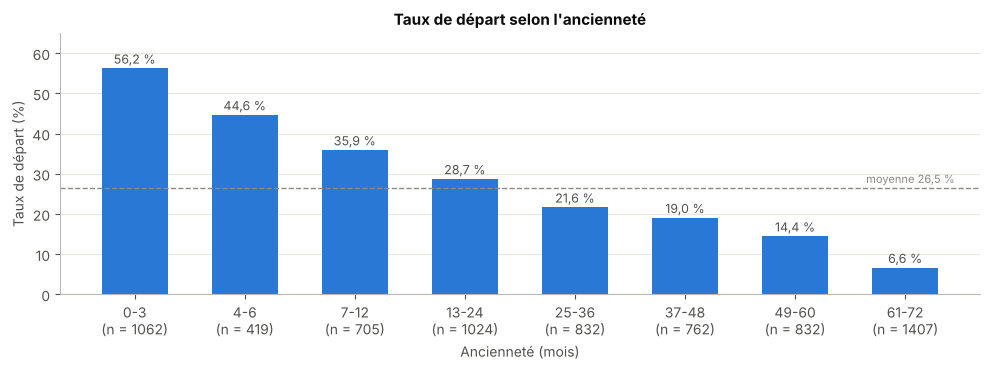

In [9]:
tranches = pd.cut(df["tenure"], bins=[-1, 3, 6, 12, 24, 36, 48, 60, 72],
                  labels=["0-3", "4-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
par_anc = df.groupby(tranches, observed=True)["Churn"].agg(taux="mean", clients="size")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar([f"{t}\n(n = {n})" for t, n in zip(par_anc.index, par_anc["clients"])],
       par_anc["taux"] * 100, color=BLEU, width=0.6)
for i, v in enumerate(par_anc["taux"]):
    ax.text(i, v * 100 + 1.2, pct(v), ha="center", fontsize=9, color="#52514e")
ax.axhline(taux * 100, color=GRIS, ls="--", lw=1)
ax.text(7.45, taux * 100 + 1.2, f"moyenne {pct(taux)}", color=GRIS, fontsize=8, ha="right")
ax.set(title="Taux de départ selon l'ancienneté", xlabel="Ancienneté (mois)", ylabel="Taux de départ (%)", ylim=(0, 65))
ax.grid(axis="x", visible=False)
plt.tight_layout()
sauver(fig, "depart_par_anciennete")

for tranche in ["0-3", "4-6", "37-48", "49-60", "61-72"]:
    R[f"churn_{tranche.replace('-', '_')}"] = float(par_anc.loc[tranche, "taux"])
R["churn_6_premiers_mois"] = float(df.loc[df["tenure"] <= 6, "Churn"].mean())
R["part_clients_6_premiers_mois"] = float((df["tenure"] <= 6).mean())
par_anc.assign(taux=par_anc["taux"].map(pct))

Le risque baisse avec l'ancienneté : 56,2 % sur les trois premiers mois, 44,6 % entre quatre et six mois, puis 14,4 % entre 49 et 60 mois et 6,6 % au-delà de cinq ans. La baisse est forte au début, puis plus lente. Une relation linéaire avec l'ancienneté la capte mal, d'où l'indicateur « nouveau client » (six premiers mois) que je teste en section 4. Ces six premiers mois concernent 21 % des clients, avec un taux de départ de 52,9 %.

### 3.4 L'effet de la fibre tient-il à contrat égal ?

Les clients fibre sont plus souvent sans engagement (69 % contre 51 % pour l'ADSL). Je vérifie que l'écart de départs ne vient pas seulement de là.

In [10]:
croise = df.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="mean")
effectifs = pd.crosstab(df["Contract"], df["InternetService"])
print("Taux de départ par contrat et accès internet :")
print(croise.map(pct).to_string())
print("\nEffectifs :")
print(effectifs.to_string())

R.update(churn_fibre_sans_eng=float(croise.loc["Month-to-month", "Fiber optic"]),
         churn_adsl_sans_eng=float(croise.loc["Month-to-month", "DSL"]),
         churn_fibre_2ans=float(croise.loc["Two year", "Fiber optic"]),
         churn_adsl_2ans=float(croise.loc["Two year", "DSL"]),
         churn_fibre_1an=float(croise.loc["One year", "Fiber optic"]),
         churn_adsl_1an=float(croise.loc["One year", "DSL"]),
         part_sans_eng_fibre=float(effectifs.loc["Month-to-month", "Fiber optic"] / effectifs["Fiber optic"].sum()),
         part_sans_eng_adsl=float(effectifs.loc["Month-to-month", "DSL"] / effectifs["DSL"].sum()))

Taux de départ par contrat et accès internet :
InternetService     DSL Fiber optic      No
Contract                                   
Month-to-month   32,2 %      54,6 %  18,9 %
One year          9,3 %      19,3 %   2,5 %
Two year          1,9 %       7,2 %   0,8 %

Effectifs :
InternetService   DSL  Fiber optic   No
Contract                               
Month-to-month   1223         2128  524
One year          570          539  364
Two year          628          429  638


L'écart tient dans chaque type de contrat : 54,6 % contre 32,2 % sans engagement, 19,3 % contre 9,3 % avec un an, 7,2 % contre 1,9 % avec deux ans. Les clients fibre paient plus cher pour un service censé être meilleur, et partent davantage. Les données ne disent pas pourquoi (prix, qualité du réseau, offres concurrentes), mais c'est la première question que je poserais à l'équipe produit.

### 3.5 Tests statistiques

Avec 7 043 clients, presque tout écart devient « significatif ». Je regarde donc surtout la taille de l'effet (V de Cramér), et j'ajuste les p-values pour les 16 tests simultanés (méthode de Benjamini-Hochberg).

In [11]:
from statsmodels.stats.multitest import multipletests

var_test = [c for c in df.columns
            if c not in ("customerID", "Churn") and not pd.api.types.is_numeric_dtype(df[c])]
var_test.append("SeniorCitizen")

lignes = []
for col in var_test:
    table = pd.crosstab(df[col], df["Churn"])
    chi2, p_value, _, _ = stats.chi2_contingency(table)
    v_cramer = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    lignes.append({"variable": col, "v_cramer": v_cramer, "p_value": p_value})

tests = pd.DataFrame(lignes)
tests["p_ajustee_bh"] = multipletests(tests["p_value"], method="fdr_bh")[1]
tests["significatif_5 %"] = tests["p_ajustee_bh"] < 0.05
tests = tests.sort_values("v_cramer", ascending=False).reset_index(drop=True)

R.update(v_contrat=float(tests.set_index("variable").loc["Contract", "v_cramer"]),
         p_genre=float(tests.set_index("variable").loc["gender", "p_value"]),
         p_phone=float(tests.set_index("variable").loc["PhoneService", "p_value"]),
         n_tests_cat=len(tests),
         n_significatifs=int(tests["significatif_5 %"].sum()))
tests

,variable,v_cramer,p_value,p_ajustee_bh,significatif_5 %
0,Contract,0.410,5.863e-258,9.381e-257,True
1,InternetService,0.322,9.572e-160,7.657e-159,True
2,PaymentMethod,0.303,3.682e-140,1.964e-139,True
3,PaperlessBilling,0.191,4.073e-58,1.629e-57,True
4,OnlineSecurity,0.171,1.232e-46,3.943e-46,True
5,TechSupport,0.164,2.924e-43,7.796e-43,True
6,Dependents,0.164,4.925e-43,1.126e-42,True
7,SeniorCitizen,0.150,1.510e-36,3.020e-36,True
8,Partner,0.150,2.140e-36,3.804e-36,True
9,OnlineBackup,0.082,6.214e-12,9.943e-12,True


Le contrat a l'effet le plus fort (V = 0,41), suivi de l'accès internet et du moyen de paiement. 14 variables sur 16 restent significatives après correction. Le genre (p = 0,49) et la souscription à la téléphonie (p = 0,34) n'ont pas de lien mesurable avec le départ. Je retire le genre du modèle : il n'apporte rien, et s'en servir pour cibler une action commerciale serait discutable.

Pour les deux variables continues, j'utilise le test de Mann-Whitney, car leurs distributions sont asymétriques, et le delta de Cliff comme taille d'effet.

In [12]:
lignes = []
for col in ["tenure", "MonthlyCharges"]:
    restants = df.loc[df["Churn"] == 0, col]
    partants = df.loc[df["Churn"] == 1, col]
    u, p_value = stats.mannwhitneyu(restants, partants, alternative="two-sided")
    # Delta de Cliff : P(restant > partant) − P(restant < partant)
    delta = 2 * u / (len(restants) * len(partants)) - 1
    lignes.append({"variable": col, "médiane restants": restants.median(),
                   "médiane partants": partants.median(), "p_value": p_value, "delta_cliff": delta})
tests_num = pd.DataFrame(lignes)
R.update(cliff_tenure=float(tests_num.loc[0, "delta_cliff"]),
         cliff_facture=float(tests_num.loc[1, "delta_cliff"]),
         mediane_anc_restants=float(tests_num.loc[0, "médiane restants"]),
         mediane_anc_partants=float(tests_num.loc[0, "médiane partants"]))
tests_num

,variable,médiane restants,médiane partants,p_value,delta_cliff
0,tenure,38.000,10.00,2.420e-208,0.480
1,MonthlyCharges,64.425,79.65,3.312e-54,-0.242


L'ancienneté sépare fortement les deux groupes : médiane de 38 mois chez les clients restés, 10 chez les partants (δ = 0,48). L'effet de la facture est plus modeste (δ = −0,24).

## 4. Protocole et choix des variables

Je crée deux variables candidates :

- `nouveau_client` : ancienneté de six mois ou moins (section 3.3) ;
- `evolution_facture` : écart entre la facture actuelle et la dépense mensuelle moyenne depuis la souscription, pour repérer une hausse récente.

Elles se calculent ligne par ligne, sans statistique sur l'ensemble du jeu : les créer avant le découpage ne fait fuiter aucune information du test.

In [13]:
df["nouveau_client"] = (df["tenure"] <= 6).astype(int)
depense_moyenne = np.where(df["tenure"] > 0, df["TotalCharges"] / df["tenure"].clip(lower=1), df["MonthlyCharges"])
df["evolution_facture"] = df["MonthlyCharges"] - depense_moyenne

df[["nouveau_client", "evolution_facture"]].describe().T

,count,mean,std,min,25%,50%,75%,max
nouveau_client,7043.0,0.210,0.408,0.0,0.000,0.0,0.000,1.000
evolution_facture,7043.0,-0.001,2.614,-18.9,-1.159,0.0,1.146,19.125


Je mets de côté 20 % des clients comme jeu de test, en conservant la proportion de partants. Ce jeu ne sert qu'une fois, à la fin (section 10). Tous les choix (variables, modèle, réglages, règle de décision) se font en validation croisée sur les 80 % restants.

In [14]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, train_test_split

train, test = train_test_split(df, test_size=0.2, stratify=df["Churn"], random_state=RANDOM_STATE)
y_train, y_test = train["Churn"].to_numpy(), test["Churn"].to_numpy()

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
METRIQUES = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "brier": "neg_brier_score"}

print(f"Apprentissage : {len(train)} clients, taux de départ {pct(y_train.mean(), 2)}")
print(f"Test          : {len(test)} clients, taux de départ {pct(y_test.mean(), 2)}")
R.update(n_train=len(train), n_test=len(test), taux_test=float(y_test.mean()))

Apprentissage : 5634 clients, taux de départ 26,54 %
Test          : 1409 clients, taux de départ 26,54 %


Pour comparer deux configurations, je ne compare pas seulement des moyennes. Les plis d'une validation croisée partagent leurs données d'apprentissage, donc leurs scores ne sont pas indépendants, et un test t classique serait trop optimiste. J'utilise la correction de Nadeau et Bengio, qui élargit la variance en conséquence.

La métrique principale est la PR-AUC, adaptée à une classe minoritaire. Le score de Brier mesure la qualité des probabilités, dont j'ai besoin pour calculer un profit. Je n'utilise pas l'accuracy : prédire « reste » pour tout le monde donnerait déjà 26,5 % d'erreur seulement.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CATEGORIES = {
    "Contract": ["Month-to-month", "One year", "Two year"],
    "InternetService": ["No", "DSL", "Fiber optic"],
    "PaymentMethod": ["Bank transfer (automatic)", "Credit card (automatic)", "Electronic check", "Mailed check"],
}
for col in ["Partner", "Dependents", "PhoneService", "MultipleLines", *OPTIONS_INTERNET, "PaperlessBilling"]:
    CATEGORIES[col] = ["No", "Yes"]
VAR_CAT = list(CATEGORIES)


def preprocesseur(numeriques, binaires):
    """Standardise les variables continues, encode les catégories (1re modalité = référence)."""
    return ColumnTransformer([
        ("num", StandardScaler(), numeriques),
        ("bin", "passthrough", binaires),
        ("cat", OneHotEncoder(categories=[CATEGORIES[c] for c in VAR_CAT], drop="first", sparse_output=False), VAR_CAT),
    ], verbose_feature_names_out=False)


def evaluer(modele, X, y):
    """Scores sur les 15 plis de la validation croisée répétée."""
    r = cross_validate(modele, X, y, cv=cv_rep, scoring=METRIQUES, n_jobs=-1)
    return pd.DataFrame({"pr_auc": r["test_pr_auc"], "roc_auc": r["test_roc_auc"], "brier": -r["test_brier"]})


def test_apparie(scores_a, scores_b, ratio_test_train=1 / 4):
    """Différence moyenne a − b sur les mêmes plis, avec la correction de Nadeau et Bengio (2003).

    Les plis d'une validation croisée partagent leurs données d'apprentissage : leurs scores ne sont
    pas indépendants. La correction élargit la variance pour en tenir compte.
    """
    d = np.asarray(scores_a) - np.asarray(scores_b)
    j = len(d)
    erreur_type = np.sqrt((1 / j + ratio_test_train) * d.var(ddof=1))
    t = d.mean() / erreur_type
    return d.mean(), erreur_type, 2 * stats.t.sf(abs(t), df=j - 1)

### 4.1 Quelles variables garder ?

Je compare quatre jeux de variables avec une régression logistique simple, sur les 15 mêmes plis.

In [16]:
from sklearn.linear_model import LogisticRegression

configurations = {
    "Variables brutes (dont MonthlyCharges et TotalCharges)": (["tenure", "MonthlyCharges", "TotalCharges"], ["SeniorCitizen"]),
    "Sans MonthlyCharges ni TotalCharges": (["tenure"], ["SeniorCitizen"]),
    "+ nouveau_client": (["tenure"], ["SeniorCitizen", "nouveau_client"]),
    "+ nouveau_client + evolution_facture": (["tenure", "evolution_facture"], ["SeniorCitizen", "nouveau_client"]),
}
scores_ablation = {}
for nom, (num, binaires) in configurations.items():
    modele = Pipeline([("pre", preprocesseur(num, binaires)), ("clf", LogisticRegression(max_iter=3000))])
    scores_ablation[nom] = evaluer(modele, train, y_train)

ref = scores_ablation["Sans MonthlyCharges ni TotalCharges"]["pr_auc"]
lignes = []
for nom, s in scores_ablation.items():
    diff, et, p = (0.0, np.nan, np.nan) if nom == "Sans MonthlyCharges ni TotalCharges" else test_apparie(s["pr_auc"], ref)
    lignes.append({"configuration": nom, "PR-AUC": s["pr_auc"].mean(), "écart-type": s["pr_auc"].std(),
                   "Brier": s["brier"].mean(), "écart vs sans montants": diff, "p (Nadeau-Bengio)": p})
ablation = pd.DataFrame(lignes).set_index("configuration")

a = ablation["PR-AUC"]
R.update(pr_ablation_brut=float(a.iloc[0]), pr_ablation_sans=float(a.iloc[1]),
         pr_ablation_nouveau=float(a.iloc[2]), pr_ablation_evol=float(a.iloc[3]),
         p_ablation_nouveau=float(ablation["p (Nadeau-Bengio)"].iloc[2]),
         p_ablation_brut=float(ablation["p (Nadeau-Bengio)"].iloc[0]),
         p_ablation_evol=float(test_apparie(scores_ablation["+ nouveau_client + evolution_facture"]["pr_auc"],
                                            scores_ablation["+ nouveau_client"]["pr_auc"])[2]))
ablation

,PR-AUC,écart-type,Brier,écart vs sans montants,p (Nadeau-Bengio)
configuration,,,,,
Variables brutes (dont MonthlyCharges et TotalCharges),0.662,0.017,0.135,0.002,0.101
Sans MonthlyCharges ni TotalCharges,0.660,0.017,0.135,0.000,NaN
+ nouveau_client,0.665,0.019,0.134,0.005,0.313
+ nouveau_client + evolution_facture,0.664,0.019,0.134,0.004,0.464


Les écarts sont faibles et aucun n'est significatif. Je décide donc sur la lisibilité :

- Retirer `MonthlyCharges` et `TotalCharges` ne coûte presque rien (PR-AUC 0,662 avec, 0,660 sans, p = 0,10). La facture découle des services, et `TotalCharges` est à peu près l'ancienneté multipliée par la facture. Je les retire pour garder des coefficients interprétables.
- `nouveau_client` apporte un gain modeste (0,665, p = 0,31). Je la garde parce qu'elle traduit directement la rupture observée en 3.3 et qu'elle se lit facilement.
- `evolution_facture` n'apporte rien de plus (0,664, p = 0,38 par rapport au jeu précédent). Je ne la garde pas.

In [17]:
VAR_NUM = ["tenure"]
VAR_BIN = ["SeniorCitizen", "nouveau_client"]
FEATURES = VAR_NUM + VAR_BIN + VAR_CAT

X_train, X_test = train[FEATURES], test[FEATURES]
valeur_train = MARGE * HORIZON * train["MonthlyCharges"].to_numpy()
valeur_test = MARGE * HORIZON * test["MonthlyCharges"].to_numpy()


def pipeline(clf):
    return Pipeline([("pre", preprocesseur(VAR_NUM, VAR_BIN)), ("clf", clf)])


print(f"{len(FEATURES)} variables d'entrée, {len(preprocesseur(VAR_NUM, VAR_BIN).fit(X_train).get_feature_names_out())} colonnes après encodage")
R.update(n_features=len(FEATURES), n_var_cat=len(VAR_CAT))

17 variables d'entrée, 21 colonnes après encodage


Le modèle utilise donc 17 variables : l'ancienneté, l'indicateur nouveau client, le statut senior et 14 variables catégorielles. La modalité de référence de chaque variable catégorielle est la première de la liste `CATEGORIES` (par exemple « sans engagement » pour le contrat).

## 5. Comparaison de modèles

Quatre modèles, évalués sur les mêmes 15 plis (validation croisée en 5 blocs, répétée 3 fois). La référence prédit le taux moyen pour tout le monde : c'est le niveau à battre.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

candidats = {
    "Référence (taux moyen)": pipeline(DummyClassifier(strategy="prior")),
    "Régression logistique": pipeline(LogisticRegression(max_iter=3000)),
    "Forêt aléatoire": pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                       random_state=RANDOM_STATE, n_jobs=1)),
    "Gradient boosting": pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}
scores_candidats = {nom: evaluer(m, X_train, y_train) for nom, m in candidats.items()}

comparaison = pd.DataFrame({
    nom: {"PR-AUC": s["pr_auc"].mean(), "écart-type PR-AUC": s["pr_auc"].std(),
          "ROC-AUC": s["roc_auc"].mean(), "Brier": s["brier"].mean()}
    for nom, s in scores_candidats.items()
}).T

for cle, nom in [("lr", "Régression logistique"), ("rf", "Forêt aléatoire"),
                 ("gb", "Gradient boosting"), ("dummy", "Référence (taux moyen)")]:
    R[f"pr_cv_{cle}"] = float(comparaison.loc[nom, "PR-AUC"])
    R[f"roc_cv_{cle}"] = float(comparaison.loc[nom, "ROC-AUC"])
    R[f"brier_cv_{cle}"] = float(comparaison.loc[nom, "Brier"])
R["et_pr_cv_lr"] = float(comparaison.loc["Régression logistique", "écart-type PR-AUC"])
comparaison

,PR-AUC,écart-type PR-AUC,ROC-AUC,Brier
Référence (taux moyen),0.265,9.756e-05,0.500,0.195
Régression logistique,0.665,1.852e-02,0.849,0.134
Forêt aléatoire,0.658,2.268e-02,0.845,0.135
Gradient boosting,0.645,2.337e-02,0.836,0.140


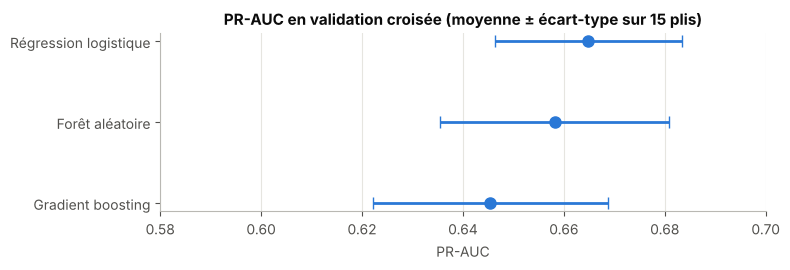

In [19]:
modeles = [n for n in comparaison.index if n != "Référence (taux moyen)"][::-1]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.errorbar(comparaison.loc[modeles, "PR-AUC"], modeles, xerr=comparaison.loc[modeles, "écart-type PR-AUC"],
            fmt="o", color=BLEU, ecolor=BLEU, elinewidth=2, capsize=4, markersize=8)
ax.set(title="PR-AUC en validation croisée (moyenne ± écart-type sur 15 plis)", xlabel="PR-AUC", xlim=(0.58, 0.70))
ax.grid(axis="y", visible=False)
plt.tight_layout()
sauver(fig, "comparaison_modeles")

La régression logistique obtient la meilleure PR-AUC (0,665), devant la forêt aléatoire (0,658) et le gradient boosting avec ses réglages par défaut (0,645). Les écarts restent de l'ordre de l'écart-type entre plis (0,019). Tous les modèles battent nettement la référence (0,265). Je règle ensuite les deux candidats les plus différents, la régression logistique et le gradient boosting, pour vérifier que le second ne prend pas l'avantage une fois optimisé.

## 6. Réglage et choix du modèle

Recherche aléatoire de 30 combinaisons par modèle, en validation croisée à 5 blocs. Pour la régression logistique, je teste aussi le type de pénalité (L1 ou L2).

In [20]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

recherche_lr = RandomizedSearchCV(
    pipeline(LogisticRegression(solver="liblinear", max_iter=3000, random_state=RANDOM_STATE)),
    {"clf__C": loguniform(1e-3, 1e2), "clf__l1_ratio": [0.0, 1.0]},  # 0 : pénalité L2, 1 : pénalité L1
    n_iter=30, scoring="average_precision", cv=cv5, random_state=RANDOM_STATE, n_jobs=-1,
).fit(X_train, y_train)

recherche_gb = RandomizedSearchCV(
    pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    {"clf__learning_rate": loguniform(0.01, 0.3), "clf__max_leaf_nodes": randint(4, 32),
     "clf__min_samples_leaf": randint(10, 120), "clf__l2_regularization": loguniform(1e-3, 10),
     "clf__max_iter": randint(100, 500)},
    n_iter=30, scoring="average_precision", cv=cv5, random_state=RANDOM_STATE, n_jobs=-1,
).fit(X_train, y_train)

for nom, r in [("Régression logistique", recherche_lr), ("Gradient boosting", recherche_gb)]:
    params = {k.replace("clf__", ""): (round(float(v), 4) if isinstance(v, float) else v) for k, v in r.best_params_.items()}
    print(f"{nom} : PR-AUC {r.best_score_:.4f} avec {params}")

R.update(lr_C=float(recherche_lr.best_params_["clf__C"]),
         lr_penalite="L1" if recherche_lr.best_params_["clf__l1_ratio"] == 1.0 else "L2")

Régression logistique : PR-AUC 0.6643 avec {'C': 0.3725, 'l1_ratio': 1.0}
Gradient boosting : PR-AUC 0.6653 avec {'l2_regularization': 0.0018, 'learning_rate': 0.0288, 'max_iter': 315, 'max_leaf_nodes': 8, 'min_samples_leaf': 108}


Avant de comparer les deux modèles réglés, je fixe la règle de choix : je garde la régression logistique, plus simple à expliquer, sauf si le gradient boosting la dépasse de plus de deux erreurs-types en PR-AUC.

In [21]:
scores_lr = evaluer(recherche_lr.best_estimator_, X_train, y_train)
scores_gb = evaluer(recherche_gb.best_estimator_, X_train, y_train)

lignes = []
for metrique in ["pr_auc", "roc_auc", "brier"]:
    diff, et, p = test_apparie(scores_gb[metrique], scores_lr[metrique])
    lignes.append({"métrique": metrique, "logistique": scores_lr[metrique].mean(),
                   "gradient boosting": scores_gb[metrique].mean(),
                   "écart (GB − LR)": diff, "erreur-type corrigée": et, "p": p})
duel = pd.DataFrame(lignes).set_index("métrique")

# Règle fixée avant de regarder le résultat : je garde le modèle le plus simple,
# sauf si le gradient boosting le dépasse de plus de deux erreurs-types en PR-AUC.
ecart_pr, et_pr = duel.loc["pr_auc", "écart (GB − LR)"], duel.loc["pr_auc", "erreur-type corrigée"]
gb_retenu = ecart_pr > 2 * et_pr
modele_final = recherche_gb.best_estimator_ if gb_retenu else recherche_lr.best_estimator_
print(f"Modèle retenu : {'gradient boosting' if gb_retenu else 'régression logistique'}\n")

R.update(pr_cv_lr_opt=float(scores_lr["pr_auc"].mean()), pr_cv_gb_opt=float(scores_gb["pr_auc"].mean()),
         roc_cv_lr_opt=float(scores_lr["roc_auc"].mean()), roc_cv_gb_opt=float(scores_gb["roc_auc"].mean()),
         brier_cv_lr_opt=float(scores_lr["brier"].mean()), brier_cv_gb_opt=float(scores_gb["brier"].mean()),
         ecart_pr_gb_lr=float(ecart_pr), et_ecart_pr=float(et_pr),
         p_ecart_pr=float(duel.loc["pr_auc", "p"]), gb_retenu=bool(gb_retenu))
duel

Modèle retenu : régression logistique



,logistique,gradient boosting,écart (GB − LR),erreur-type corrigée,p
métrique,,,,,
pr_auc,0.665,0.666,1.408e-03,5.535e-03,0.803
roc_auc,0.849,0.848,-1.572e-03,1.720e-03,0.376
brier,0.134,0.134,5.040e-04,7.635e-04,0.520


Une fois réglé, le gradient boosting rattrape la régression logistique (PR-AUC 0,666 contre 0,665), mais l'écart (+0,0014) est bien plus petit que son erreur-type (0,0055, p = 0,80). Les deux modèles sont indiscernables. Je retiens la régression logistique avec pénalité L1 (C = 0,37) : mêmes performances, et des coefficients qu'une équipe marketing peut lire.

## 7. Déséquilibre des classes

Avec 26,5 % de partants, le déséquilibre est réel mais modéré. Je compare l'absence de correction et la pondération des classes. Je n'utilise pas SMOTE : sur des variables surtout catégorielles codées en 0/1, il crée des clients fictifs aux valeurs intermédiaires, et il pose le même problème de calibration que la pondération.

In [22]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

variantes = {
    "Aucune correction": clone(modele_final),
    "Pondération des classes": clone(modele_final).set_params(clf__class_weight="balanced"),
}
lignes = []
for nom, m in variantes.items():
    s = evaluer(m, X_train, y_train)
    p_oof = cross_val_predict(m, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
    lignes.append({"stratégie": nom, "PR-AUC": s["pr_auc"].mean(), "ROC-AUC": s["roc_auc"].mean(),
                   "Brier": s["brier"].mean(), "probabilité moyenne prédite": p_oof.mean()})
desequilibre = pd.DataFrame(lignes).set_index("stratégie")
desequilibre.loc["(taux réel)", "probabilité moyenne prédite"] = y_train.mean()

R.update(brier_pondere=float(desequilibre.loc["Pondération des classes", "Brier"]),
         brier_sans_ponderation=float(desequilibre.loc["Aucune correction", "Brier"]),
         proba_moy_pondere=float(desequilibre.loc["Pondération des classes", "probabilité moyenne prédite"]),
         pr_pondere=float(desequilibre.loc["Pondération des classes", "PR-AUC"]))
desequilibre

,PR-AUC,ROC-AUC,Brier,probabilité moyenne prédite
stratégie,,,,
Aucune correction,0.665,0.849,0.134,0.266
Pondération des classes,0.664,0.849,0.163,0.414
(taux réel),NaN,NaN,NaN,0.265


La pondération ne change presque pas le classement des clients (PR-AUC 0,664) mais dégrade le score de Brier (0,163 contre 0,134). La dernière colonne montre pourquoi : avec pondération, le modèle prédit en moyenne 41,4 % de départs, alors que le taux réel est de 26,5 %. Ses probabilités sont gonflées. Comme la règle de contact utilise les probabilités elles-mêmes, je garde le modèle sans correction et je traite le déséquilibre dans la règle de décision.

## 8. Calibration

La règle de contact multiplie la probabilité par la valeur du client : une probabilité de 0,4 doit vraiment correspondre à 40 % de départs. Je le vérifie sur des prédictions hors échantillon (chaque client est prédit par un modèle qui ne l'a pas vu), et je compare avec deux recalibrations.

In [23]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score


def erreur_calibration(y, p, n_bins=10):
    """Écart moyen pondéré entre probabilité prédite et fréquence observée (déciles de probabilité)."""
    bornes = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    groupes = np.clip(np.searchsorted(bornes, p, side="right") - 1, 0, n_bins - 1)
    return sum(abs(y[groupes == g].mean() - p[groupes == g].mean()) * (groupes == g).mean()
               for g in range(n_bins) if (groupes == g).any())


proba_oof = cross_val_predict(modele_final, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
probas_calib = {"Sans recalibration": proba_oof}
for methode in ["sigmoid", "isotonic"]:
    calib = CalibratedClassifierCV(modele_final, method=methode, cv=5)
    probas_calib[f"Recalibration {'sigmoïde' if methode == 'sigmoid' else 'isotonique'}"] = \
        cross_val_predict(calib, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]

calibration = pd.DataFrame({
    nom: {"Brier": brier_score_loss(y_train, p), "erreur de calibration": erreur_calibration(y_train, p),
          "PR-AUC": average_precision_score(y_train, p)}
    for nom, p in probas_calib.items()
}).T

R.update(brier_oof=float(calibration.loc["Sans recalibration", "Brier"]),
         ece_oof=float(calibration.loc["Sans recalibration", "erreur de calibration"]),
         brier_iso=float(calibration.loc["Recalibration isotonique", "Brier"]),
         brier_sig=float(calibration.loc["Recalibration sigmoïde", "Brier"]),
         pr_oof=float(average_precision_score(y_train, proba_oof)),
         ece_oof_pts=100 * float(calibration.loc["Sans recalibration", "erreur de calibration"]))
calibration

,Brier,erreur de calibration,PR-AUC
Sans recalibration,0.134,0.012,0.661
Recalibration sigmoïde,0.134,0.011,0.661
Recalibration isotonique,0.134,0.013,0.659


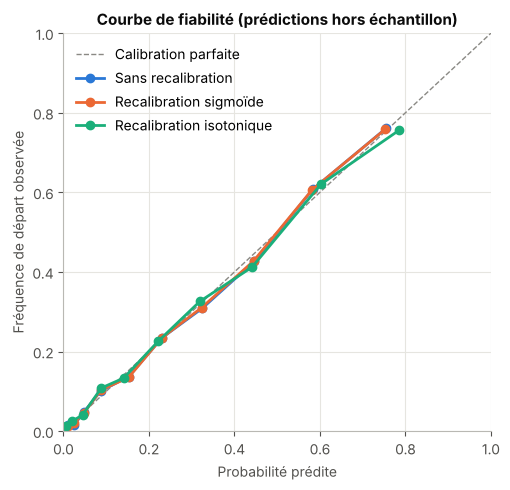

In [24]:
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Calibration parfaite")
for (nom, p), couleur in zip(probas_calib.items(), [BLEU, ORANGE, VERT]):
    frac, moy = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
    ax.plot(moy, frac, marker="o", lw=2, markersize=6, color=couleur, label=nom)
ax.set(title="Courbe de fiabilité (prédictions hors échantillon)", xlabel="Probabilité prédite",
       ylabel="Fréquence de départ observée", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left")
plt.tight_layout()
sauver(fig, "calibration")

Le modèle est déjà bien calibré : l'écart moyen entre probabilité prédite et fréquence observée est de 1,2 point, et aucune recalibration n'améliore le score de Brier (0,1340 sans, 0,1340 avec la sigmoïde, 0,1343 avec l'isotonique). Je n'en ajoute pas. C'est attendu pour une régression logistique sans pondération, dont l'apprentissage optimise directement la vraisemblance des probabilités.

## 9. Règle de décision

Deux façons de choisir qui contacter :

1. un seuil unique de probabilité, réglé pour maximiser le profit ;
2. la règle valeur : contacter si p × taux de rétention × valeur du client ≥ coût de l'offre. Elle ne demande aucun réglage si les probabilités sont bien calibrées.

Je les compare sur les prédictions hors échantillon du jeu d'apprentissage. Pour un partant contacté, je compte le profit espéré (taux de rétention × valeur − coût), puisqu'on ne sait pas à l'avance s'il acceptera l'offre.

In [25]:
def profit(contacte, y, valeur, taux_retention=TAUX_RETENTION, cout=COUT_OFFRE):
    """Profit attendu d'une campagne : chaque partant contacté rapporte taux × valeur, chaque contact coûte."""
    contacte = np.asarray(contacte, dtype=bool)
    return float(np.sum(np.where(contacte, y * taux_retention * valeur - cout, 0.0)))


def regle_valeur(p, valeur, taux_retention=TAUX_RETENTION, cout=COUT_OFFRE, k=1.0):
    """Contacter si le gain espéré du contact dépasse son coût."""
    return p * taux_retention * valeur >= k * cout


seuils = np.round(np.arange(0.05, 0.951, 0.005), 3)
profits_seuil = np.array([profit(proba_oof >= s, y_train, valeur_train) for s in seuils])
seuil_opt = float(seuils[profits_seuil.argmax()])

ks = np.round(np.arange(0.5, 2.001, 0.05), 2)
profits_k = np.array([profit(regle_valeur(proba_oof, valeur_train, k=k), y_train, valeur_train) for k in ks])
k_opt = float(ks[profits_k.argmax()])

strategies_oof = {
    "Contacter tout le monde": np.ones(len(y_train), bool),
    "Seuil 0,5": proba_oof >= 0.5,
    f"Seuil optimisé ({seuil_opt:.3f})".replace(".", ","): proba_oof >= seuil_opt,
    "Règle valeur": regle_valeur(proba_oof, valeur_train),
}
decision_oof = pd.DataFrame({
    nom: {"clients contactés": int(c.sum()), "part de la base": c.mean(),
          "profit attendu ($)": profit(c, y_train, valeur_train)}
    for nom, c in strategies_oof.items()
}).T.astype({"clients contactés": int})
print(f"Seuil uniforme optimal : {seuil_opt:.3f} | multiplicateur optimal de la règle valeur : k = {k_opt:.2f}\n")

R.update(seuil_opt=seuil_opt, k_opt=k_opt,
         profit_oof_tous=profit(strategies_oof["Contacter tout le monde"], y_train, valeur_train),
         profit_oof_seuil05=profit(proba_oof >= 0.5, y_train, valeur_train),
         profit_oof_seuil_opt=float(profits_seuil.max()),
         profit_oof_valeur=profit(regle_valeur(proba_oof, valeur_train), y_train, valeur_train),
         n_oof_valeur=int(regle_valeur(proba_oof, valeur_train).sum()), n_oof_seuil=int((proba_oof >= seuil_opt).sum()))
decision_oof

Seuil uniforme optimal : 0.505 | multiplicateur optimal de la règle valeur : k = 1.05



,clients contactés,part de la base,profit attendu ($)
Contacter tout le monde,5634,1.000,-136591.29
"Seuil 0,5",1181,0.210,45837.33
"Seuil optimisé (0,505)",1154,0.205,46092.21
Règle valeur,1415,0.251,48719.85


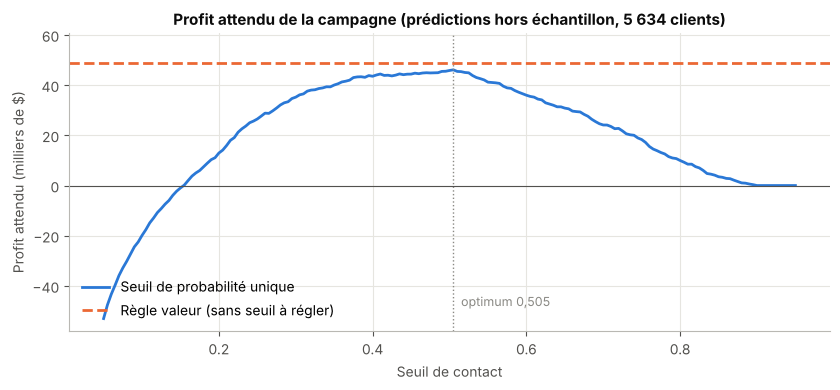

In [26]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(seuils, profits_seuil / 1000, color=BLEU, lw=2, label="Seuil de probabilité unique")
ax.axhline(R["profit_oof_valeur"] / 1000, color=ORANGE, lw=2, ls="--", label="Règle valeur (sans seuil à régler)")
ax.axvline(seuil_opt, color=GRIS, lw=1, ls=":")
ax.axhline(0, color="#52514e", lw=0.8)
ax.text(seuil_opt + 0.01, profits_seuil.min() / 1000 + 5, f"optimum {seuil_opt:.3f}".replace(".", ","),
        color=GRIS, fontsize=9)
ax.set(title=f"Profit attendu de la campagne (prédictions hors échantillon, {len(y_train):,} clients)".replace(",", " ").replace("échantillon  ", "échantillon, "),
       ylim=(profits_seuil.min() / 1000 - 5, R["profit_oof_valeur"] / 1000 + 12),
       xlabel="Seuil de contact", ylabel="Profit attendu (milliers de $)")
ax.legend(loc="lower left")
plt.tight_layout()
sauver(fig, "profit_seuil")

Le meilleur seuil unique est 0,505 ; il rapporte 46 092 $ en contactant 1 154 clients. La règle valeur rapporte 48 720 $ sans aucun réglage : elle contacte un peu plus de clients (1 415), en descendant plus bas en probabilité quand la facture est élevée. Si je multiplie son coût par un facteur k, le profit est maximal pour k = 1,05, très proche de 1, ce qu'on attend de probabilités bien calibrées. Contacter tout le monde donnerait −136 591 $.

## 10. Évaluation finale sur le jeu de test

Le jeu de test (1 409 clients) n'a servi à aucun choix. J'entraîne le modèle retenu sur tout le jeu d'apprentissage et je l'évalue une seule fois, avec des intervalles de confiance par bootstrap (1 000 tirages).

In [27]:
modele_final.fit(X_train, y_train)
proba_test = modele_final.predict_proba(X_test)[:, 1]

rng = np.random.default_rng(RANDOM_STATE)
boot = {"PR-AUC": [], "ROC-AUC": [], "Brier": []}
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    boot["PR-AUC"].append(average_precision_score(y_test[i], proba_test[i]))
    boot["ROC-AUC"].append(roc_auc_score(y_test[i], proba_test[i]))
    boot["Brier"].append(brier_score_loss(y_test[i], proba_test[i]))

resultats_test = pd.DataFrame({
    "valeur": [average_precision_score(y_test, proba_test), roc_auc_score(y_test, proba_test),
               brier_score_loss(y_test, proba_test)],
    "IC 95 % bas": [np.percentile(boot[m], 2.5) for m in boot],
    "IC 95 % haut": [np.percentile(boot[m], 97.5) for m in boot],
}, index=list(boot))

for m, cle in [("PR-AUC", "pr"), ("ROC-AUC", "roc"), ("Brier", "brier")]:
    R[f"{cle}_test"] = float(resultats_test.loc[m, "valeur"])
    R[f"{cle}_test_bas"] = float(resultats_test.loc[m, "IC 95 % bas"])
    R[f"{cle}_test_haut"] = float(resultats_test.loc[m, "IC 95 % haut"])
R["ratio_pr_hasard"] = R["pr_test"] / y_test.mean()
R["ece_test"] = float(erreur_calibration(y_test, proba_test))
R["ece_test_pts"] = 100 * R["ece_test"]
resultats_test

,valeur,IC 95 % bas,IC 95 % haut
PR-AUC,0.654,0.601,0.704
ROC-AUC,0.846,0.824,0.867
Brier,0.136,0.125,0.145


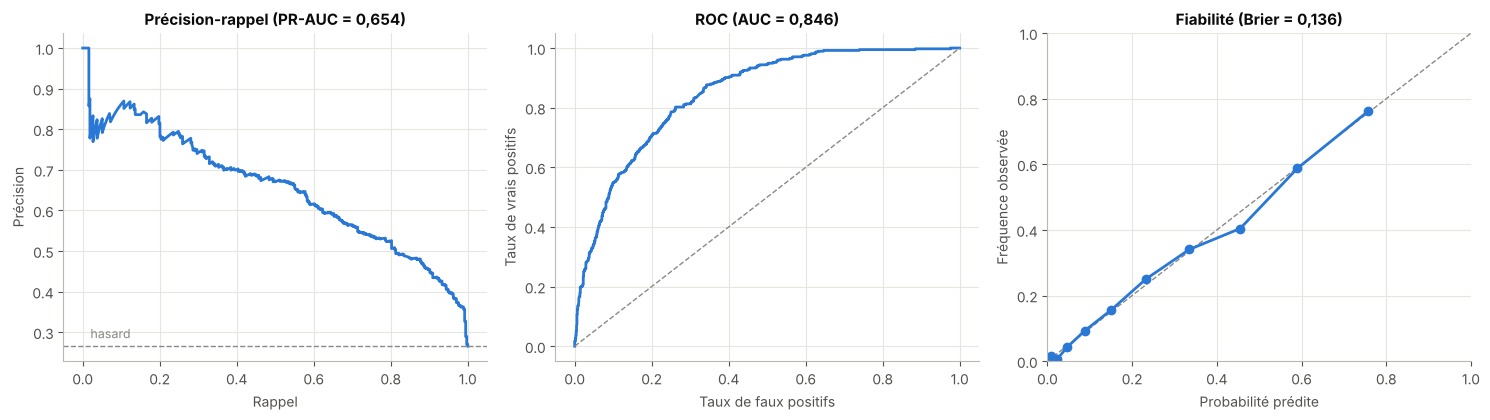

In [28]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
prec, rapp, _ = precision_recall_curve(y_test, proba_test)
axes[0].plot(rapp, prec, color=BLEU, lw=2)
axes[0].axhline(y_test.mean(), color=GRIS, ls="--", lw=1)
axes[0].text(0.02, y_test.mean() + 0.02, "hasard", color=GRIS, fontsize=9)
axes[0].set(title=f"Précision-rappel (PR-AUC = {R['pr_test']:.3f})".replace(".", ","), xlabel="Rappel", ylabel="Précision")

fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[1].plot(fpr, tpr, color=BLEU, lw=2)
axes[1].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
axes[1].set(title=f"ROC (AUC = {R['roc_test']:.3f})".replace(".", ","), xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs")

frac, moy = calibration_curve(y_test, proba_test, n_bins=10, strategy="quantile")
axes[2].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
axes[2].plot(moy, frac, marker="o", color=BLEU, lw=2, markersize=6)
axes[2].set(title=f"Fiabilité (Brier = {R['brier_test']:.3f})".replace(".", ","), xlabel="Probabilité prédite",
            ylabel="Fréquence observée", xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()
sauver(fig, "evaluation_test")

Les performances sur le test sont cohérentes avec la validation croisée : PR-AUC de 0,654 [0,601 ; 0,704], soit 2,5 fois le niveau du hasard, et ROC-AUC de 0,846. La courbe de fiabilité reste proche de la diagonale (écart moyen de 1,2 point).

### 10.1 Profit des stratégies de contact

In [29]:
strategies = {
    "Contacter tout le monde": np.ones(len(y_test), bool),
    "Seuil 0,5": proba_test >= 0.5,
    f"Seuil optimisé ({seuil_opt:.3f})".replace(".", ","): proba_test >= seuil_opt,
    "Règle valeur": regle_valeur(proba_test, valeur_test),
    "Oracle (départs connus)": (y_test == 1) & (TAUX_RETENTION * valeur_test >= COUT_OFFRE),
}
profit_oracle = profit(strategies["Oracle (départs connus)"], y_test, valeur_test)
decision_test = pd.DataFrame({
    nom: {"contactés": int(c.sum()), "part de la base": c.mean(),
          "partants touchés": int((c & (y_test == 1)).sum()),
          "précision": (y_test[c].mean() if c.any() else np.nan),
          "profit attendu ($)": profit(c, y_test, valeur_test),
          "part du profit de l'oracle": profit(c, y_test, valeur_test) / profit_oracle}
    for nom, c in strategies.items()
}).T.astype({"contactés": int, "partants touchés": int})

# Incertitude : bootstrap apparié sur les clients du test
c_valeur = strategies["Règle valeur"]
c_seuil = proba_test >= seuil_opt
rng = np.random.default_rng(RANDOM_STATE)
p_val, p_diff = [], []
for _ in range(2000):
    i = rng.integers(0, len(y_test), len(y_test))
    a = profit(c_valeur[i], y_test[i], valeur_test[i])
    p_val.append(a)
    p_diff.append(a - profit(c_seuil[i], y_test[i], valeur_test[i]))
print(f"Profit règle valeur : {usd(profit(c_valeur, y_test, valeur_test))} "
      f"[IC 95 % : {usd(np.percentile(p_val, 2.5))} ; {usd(np.percentile(p_val, 97.5))}]")
print(f"Écart règle valeur − seuil optimisé : {usd(np.mean(p_diff))} "
      f"[IC 95 % : {usd(np.percentile(p_diff, 2.5))} ; {usd(np.percentile(p_diff, 97.5))}]\n")

ligne = decision_test.loc["Règle valeur"]
ligne_seuil = decision_test.iloc[2]
R.update(test_valeur_contactes=int(ligne["contactés"]), test_valeur_part=float(ligne["part de la base"]),
         test_valeur_touches=int(ligne["partants touchés"]), test_valeur_precision=float(ligne["précision"]),
         test_valeur_profit=float(ligne["profit attendu ($)"]),
         test_valeur_profit_par_client=float(ligne["profit attendu ($)"]) / len(y_test),
         test_valeur_part_oracle=float(ligne["part du profit de l'oracle"]),
         test_valeur_ic_bas=float(np.percentile(p_val, 2.5)), test_valeur_ic_haut=float(np.percentile(p_val, 97.5)),
         test_seuil_contactes=int(ligne_seuil["contactés"]), test_seuil_profit=float(ligne_seuil["profit attendu ($)"]),
         test_seuil_part_oracle=float(ligne_seuil["part du profit de l'oracle"]),
         test_diff_valeur_seuil=float(np.mean(p_diff)),
         test_diff_ic_bas=float(np.percentile(p_diff, 2.5)), test_diff_ic_haut=float(np.percentile(p_diff, 97.5)),
         test_tous_profit=float(decision_test.loc["Contacter tout le monde", "profit attendu ($)"]),
         test_seuil05_profit=float(decision_test.loc["Seuil 0,5", "profit attendu ($)"]),
         test_oracle_profit=profit_oracle,
         test_partants=int(y_test.sum()),
         test_partants_hors_portee=int(((y_test == 1) & (TAUX_RETENTION * valeur_test < COUT_OFFRE)).sum()))
decision_test

Profit règle valeur : 10 732 $ [IC 95 % : 7 742 $ ; 13 622 $]
Écart règle valeur − seuil optimisé : 763 $ [IC 95 % : -802 $ ; 2 411 $]



,contactés,part de la base,partants touchés,précision,profit attendu ($),part du profit de l'oracle
Contacter tout le monde,1409,1.000,374,0.265,-35553.18,-1.302
"Seuil 0,5",298,0.211,200,0.671,10287.30,0.377
"Seuil optimisé (0,505)",287,0.204,193,0.672,9938.58,0.364
Règle valeur,363,0.258,212,0.584,10732.50,0.393
Oracle (départs connus),335,0.238,335,1.000,27307.59,1.000


Sur le test, la règle valeur contacte 363 clients (26 % de la base) et touche 212 des 374 partants. Le profit attendu est de 10 732 $ [IC 95 % : 7 742 $ à 13 622 $], soit 7,62 $ par client du jeu de test. Contacter tout le monde donnerait −35 553 $.

Trois remarques :

- La règle valeur fait un peu mieux que le seuil optimisé (+763 $), mais l'intervalle de confiance de l'écart contient zéro (−802 $ à 2 411 $). Sur 1 409 clients, je ne peux pas affirmer qu'elle est meilleure. Je la préfère parce qu'elle n'a aucun paramètre à régler et qu'elle s'ajuste d'elle-même si les hypothèses économiques changent (section 10.3).
- L'« oracle » contacte exactement les partants pour qui l'offre est rentable : c'est le maximum atteignable avec ces hypothèses (27 308 $). La règle valeur en obtient 39 %.
- 39 partants du test ont une facture trop faible pour qu'un contact soit rentable. Aucune règle ne devrait les cibler avec cette offre.

### 10.2 Si l'équipe ne peut appeler qu'un nombre limité de clients

,clients,Classement par probabilité de départ,Classement par gain espéré
capacité (part de la base),,,
5 %,70,4680.0,4079.0
10 %,141,6935.0,7799.0
20 %,282,9858.0,10306.0
30 %,423,9012.0,9640.0


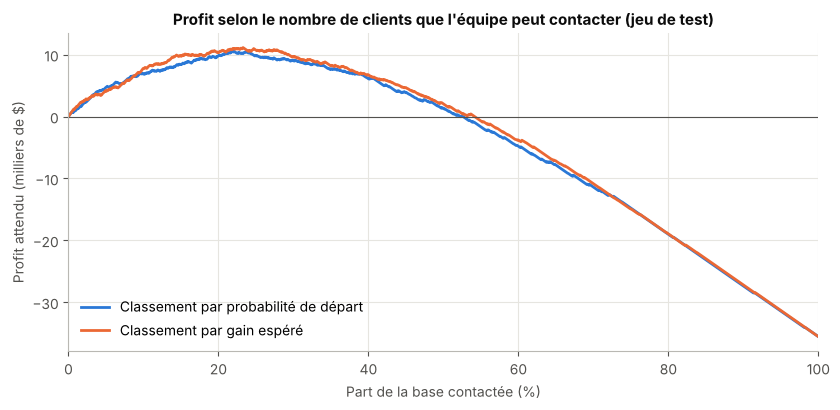

In [30]:
gain_attendu = proba_test * TAUX_RETENTION * valeur_test - COUT_OFFRE
gain_reel = y_test * TAUX_RETENTION * valeur_test - COUT_OFFRE
n = len(y_test)
parts = np.arange(n + 1) / n
courbes = {
    "Classement par probabilité de départ": np.concatenate([[0], np.cumsum(gain_reel[np.argsort(-proba_test)])]),
    "Classement par gain espéré": np.concatenate([[0], np.cumsum(gain_reel[np.argsort(-gain_attendu)])]),
}

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for (nom, c), couleur in zip(courbes.items(), [BLEU, ORANGE]):
    ax.plot(parts * 100, c / 1000, color=couleur, lw=2, label=nom)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set(title="Profit selon le nombre de clients que l'équipe peut contacter (jeu de test)",
       xlabel="Part de la base contactée (%)", ylabel="Profit attendu (milliers de $)", xlim=(0, 100))
ax.legend(loc="lower left")
plt.tight_layout()
sauver(fig, "profit_capacite")

lignes = []
for part in [0.05, 0.10, 0.20, 0.30]:
    k = int(round(part * n))
    lignes.append({"capacité (part de la base)": pct(part, 0), "clients": k,
                   **{nom: c[k] for nom, c in courbes.items()}})
capacite = pd.DataFrame(lignes).set_index("capacité (part de la base)")
for part, cle in [(0.05, "05"), (0.10, "10"), (0.20, "20"), (0.30, "30")]:
    k = int(round(part * n))
    R[f"cap{cle}_proba"] = float(courbes["Classement par probabilité de départ"][k])
    R[f"cap{cle}_gain"] = float(courbes["Classement par gain espéré"][k])
courbe_gain = courbes["Classement par gain espéré"]
R.update(cap_part_max=float(parts[courbe_gain.argmax()]), cap_profit_max=float(courbe_gain.max()))
capacite.round(0)

Quand la capacité d'appel est limitée, il faut classer les clients. Classer par gain espéré plutôt que par probabilité donne un profit un peu plus élevé à 10 % de la base (7 799 $ contre 6 935 $) et à 20 % (10 306 $ contre 9 858 $), mais pas à 5 % (4 079 $ contre 4 680 $). Les deux courbes restent proches. Le profit culmine vers 23 % de la base (11 136 $), puis baisse : au-delà, chaque appel supplémentaire coûte plus qu'il ne rapporte. Ce maximum est lu après coup sur le test, avec les départs connus ; il indique un ordre de grandeur, pas une cible. La règle valeur, fixée sans regarder le test, contacte 26 % de la base, ce qui est proche.

### 10.3 Sensibilité aux hypothèses

Le taux de rétention de 30 % est l'hypothèse la plus fragile. Je regarde deux situations : la campagne est dimensionnée avec 30 % mais le vrai taux est différent ; puis les hypothèses sont justes mais prennent d'autres valeurs.

In [31]:
# 1. La règle est construite avec un taux de rétention supposé de 30 %. Que se passe-t-il si le vrai taux diffère ?
contactes = regle_valeur(proba_test, valeur_test)
valeur_partants_contactes = np.sum(valeur_test[contactes & (y_test == 1)])
taux_rentabilite = COUT_OFFRE * contactes.sum() / valeur_partants_contactes
lignes = [{"taux de rétention réel": pct(t, 0),
           "profit attendu ($)": profit(contactes, y_test, valeur_test, taux_retention=t)}
          for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]]
print(f"Campagne dimensionnée pour 30 % : elle perd de l'argent si l'offre retient moins de {pct(taux_rentabilite)} des partants.")
R["taux_rentabilite"] = float(taux_rentabilite)
mauvaise_hypothese = pd.DataFrame(lignes).set_index("taux de rétention réel")
mauvaise_hypothese

Campagne dimensionnée pour 30 % : elle perd de l'argent si l'offre retient moins de 20,1 % des partants.


,profit attendu ($)
taux de rétention réel,
5 %,-16361.25
10 %,-10942.50
15 %,-5523.75
20 %,-105.00
30 %,10732.50
40 %,21570.00


C'est le chiffre le plus important pour le métier : si l'offre retient moins de 20,1 % des partants contactés, la campagne telle que dimensionnée perd de l'argent. Il faut mesurer ce taux avant de généraliser (section 15).

In [32]:
# 2. Si les hypothèses sont justes mais différentes : profit et volume de la campagne réoptimisée
lignes = []
for marge in [0.3, 0.5, 0.7]:
    for t in [0.10, 0.20, 0.30, 0.40]:
        valeur = marge * HORIZON * test["MonthlyCharges"].to_numpy()
        c = regle_valeur(proba_test, valeur, taux_retention=t)
        lignes.append({"marge": pct(marge, 0), "taux de rétention": pct(t, 0),
                       "profit attendu ($)": profit(c, y_test, valeur, taux_retention=t), "part contactée": c.mean()})
grille_sens = pd.DataFrame(lignes)
R["sens_profit_m50_t10"] = float(grille_sens.query("marge == '50 %' and `taux de rétention` == '10 %'")["profit attendu ($)"].iloc[0])
R["sens_part_m50_t10"] = float(grille_sens.query("marge == '50 %' and `taux de rétention` == '10 %'")["part contactée"].iloc[0])
R["sens_profit_m50_t40"] = float(grille_sens.query("marge == '50 %' and `taux de rétention` == '40 %'")["profit attendu ($)"].iloc[0])
grille_sens.pivot(index="taux de rétention", columns="marge", values="profit attendu ($)").round(0)

marge,30 %,50 %,70 %
taux de rétention,,,
10 %,0.0,0.0,156.0
20 %,101.0,2301.0,8902.0
30 %,1016.0,10732.0,23702.0
40 %,4933.0,21321.0,41433.0


Quand les hypothèses changent, la règle valeur s'adapte : avec une marge de 50 % et un taux de rétention de 10 %, elle ne contacte plus personne (profit de 0 $) au lieu de perdre de l'argent ; avec 40 %, le profit atteint 21 321 $.

## 11. Segmentation risque × valeur

Pour donner au marketing une vue d'ensemble, j'applique le modèle à toute la base. Chaque client reçoit une probabilité hors échantillon : prédiction en validation croisée pour les clients d'apprentissage, prédiction du modèle final pour ceux du test. Je croise ensuite le risque (probabilité ≥ 0,5) et la facture (au-dessus ou au-dessous de la médiane, 70,35 $).

In [33]:
proba_toutes = pd.Series(np.nan, index=df.index)
proba_toutes.loc[train.index] = proba_oof
proba_toutes.loc[test.index] = proba_test

base = df.assign(proba=proba_toutes, valeur=MARGE * HORIZON * df["MonthlyCharges"])
facture_mediane = df["MonthlyCharges"].median()
base["risque"] = np.where(base["proba"] >= 0.5, "Risque élevé (p ≥ 0,5)", "Risque faible (p < 0,5)")
base["facture"] = np.where(base["MonthlyCharges"] >= facture_mediane, "Facture élevée", "Facture faible")
base["contacte"] = regle_valeur(base["proba"].to_numpy(), base["valeur"].to_numpy())
base["ca_a_risque"] = base["proba"] * base["MonthlyCharges"]

segments = base.groupby(["risque", "facture"]).agg(
    clients=("customerID", "size"), depart_observe=("Churn", "mean"), facture_moyenne=("MonthlyCharges", "mean"),
    ca_mensuel_a_risque=("ca_a_risque", "sum"), part_contactee=("contacte", "mean"))
segments["part des clients"] = segments["clients"] / len(base)
segments["part du CA à risque"] = segments["ca_mensuel_a_risque"] / base["ca_a_risque"].sum()
ACTIONS = {
    ("Risque élevé (p ≥ 0,5)", "Facture élevée"): "Appel conseiller + offre de rétention",
    ("Risque élevé (p ≥ 0,5)", "Facture faible"): "Action peu coûteuse : e-mail, proposition de contrat engageant",
    ("Risque faible (p < 0,5)", "Facture élevée"): "Fidélisation sans remise (qualité de service)",
    ("Risque faible (p < 0,5)", "Facture faible"): "Aucune action ciblée",
}
segments = segments.reindex(list(ACTIONS))
segments["action proposée"] = [ACTIONS[i] for i in segments.index]

R["facture_mediane"] = float(facture_mediane)
R["n_contactes_base"] = int(base["contacte"].sum())
R["part_contactes_base"] = float(base["contacte"].mean())
cle = ("Risque élevé (p ≥ 0,5)", "Facture élevée")
R.update(seg_hh_clients=int(segments.loc[cle, "clients"]), seg_hh_part=float(segments.loc[cle, "part des clients"]),
         seg_hh_ca_risque=float(segments.loc[cle, "part du CA à risque"]),
         seg_hh_depart=float(segments.loc[cle, "depart_observe"]),
         seg_hh_contacte=float(segments.loc[cle, "part_contactee"]))
cle = ("Risque élevé (p ≥ 0,5)", "Facture faible")
R.update(seg_hf_clients=int(segments.loc[cle, "clients"]), seg_hf_depart=float(segments.loc[cle, "depart_observe"]),
         seg_hf_contacte=float(segments.loc[cle, "part_contactee"]),
         seg_hf_facture=float(segments.loc[cle, "facture_moyenne"]))
segments

clients  depart_observe  facture_moyenne  ca_mensuel_a_risque  part_contactee  \
risque                  facture                                                                                         
Risque élevé (p ≥ 0,5)  Facture élevée     1186           0.675           87.512            69235.557           1.000   
                        Facture faible      293           0.672           53.196            10054.489           0.498   
Risque faible (p < 0,5) Facture élevée     2338           0.187           92.118            42064.406           0.187   
                        Facture faible     3226           0.135           37.622            18449.463           0.002   

                                        part des clients  part du CA à risque  \
risque                  facture                                                 
Risque élevé (p ≥ 0,5)  Facture élevée             0.168                0.495   
                        Facture faible             0.042                0.072   
Risque faible (p < 0,5) Facture élevée             0.332                0.301   
                        Facture faible             0.458                0.132   

                                                                          action proposée  
risque                  facture                                                            
Risque élevé (p ≥ 0,5)  Facture élevée              Appel conseiller + offre de rétention  
                        Facture faible  Action peu coûteuse : e-mail, proposition de c...  
Risque faible (p < 0,5) Facture élevée      Fidélisation sans remise (qualité de service)  
                        Facture faible                               Aucune action ciblée

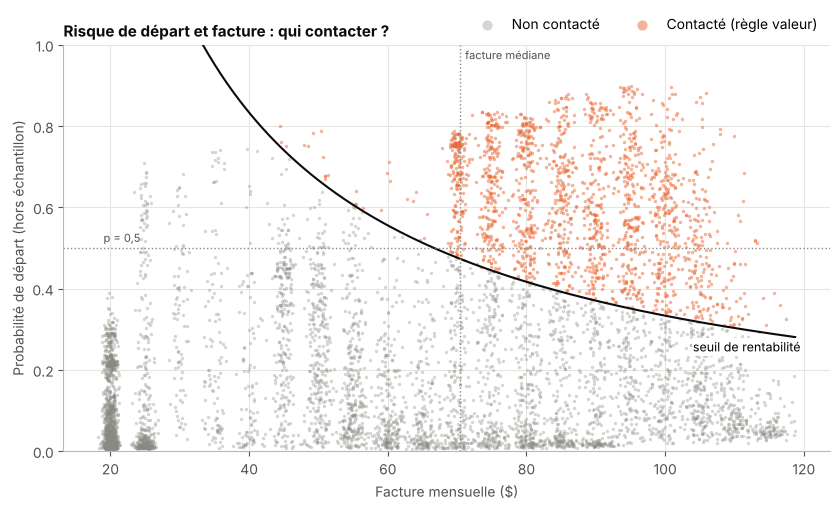

In [34]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
non = base[~base["contacte"]]
oui = base[base["contacte"]]
ax.scatter(non["MonthlyCharges"], non["proba"], s=6, alpha=0.35, color=GRIS, label="Non contacté", linewidths=0)
ax.scatter(oui["MonthlyCharges"], oui["proba"], s=6, alpha=0.5, color=ORANGE, label="Contacté (règle valeur)", linewidths=0)
x = np.linspace(facture_min, base["MonthlyCharges"].max(), 200)
ax.plot(x, COUT_OFFRE / (TAUX_RETENTION * MARGE * HORIZON * x), color="#0b0b0b", lw=1.5)
ax.text(104, COUT_OFFRE / (TAUX_RETENTION * MARGE * HORIZON * 104) - 0.075, "seuil de rentabilité", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.text(facture_mediane + 0.8, 0.965, "facture médiane", color="#52514e", fontsize=8)
ax.text(19, 0.515, "p = 0,5", color="#52514e", fontsize=8)
ax.axvline(facture_mediane, color=GRIS, ls=":", lw=1)
ax.axhline(0.5, color=GRIS, ls=":", lw=1)
ax.set(xlabel="Facture mensuelle ($)", ylabel="Probabilité de départ (hors échantillon)", ylim=(0, 1))
ax.set_title("Risque de départ et facture : qui contacter ?", loc="left")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, markerscale=3)
plt.tight_layout()
sauver(fig, "risque_valeur")

Lecture pour le marketing :

- Le segment **risque élevé, facture élevée** regroupe 1 186 clients (17 % de la base) mais 50 % de la facturation à risque. La règle valeur les contacte tous (100 %). C'est la priorité.
- Le segment **risque élevé, facture faible** part autant (67 %), avec une facture moyenne de 53 $. L'offre à 60 $ n'y est rentable que pour 50 % des clients. Pour les autres, il faut une action moins chère : un e-mail, ou une proposition de passage à un contrat engageant.
- Sur la figure, la courbe noire est la frontière de rentabilité : plus la facture est élevée, plus le risque suffisant pour justifier un appel est bas. Au total, la règle contacte 1 778 clients, soit 25 % de la base.

## 12. Interprétation

Trois lectures complémentaires du modèle final : ses coefficients (effet moyen), l'importance par permutation sur le test (apport à la prédiction) et SHAP (contribution client par client). Pour une régression logistique, SHAP se calcule exactement : c'est le coefficient multiplié par l'écart de la variable à sa moyenne.

### 12.1 Coefficients

In [35]:
if gb_retenu:
    raise RuntimeError("Les sections d'interprétation suivantes supposent la régression logistique.")

pre = modele_final.named_steps["pre"]
clf = modele_final.named_steps["clf"]
noms = pre.get_feature_names_out()
coefs = pd.Series(clf.coef_[0], index=noms)
odds = pd.DataFrame({"coefficient": coefs, "odds ratio": np.exp(coefs)})
odds = odds.reindex(odds["coefficient"].abs().sort_values(ascending=False).index)

print(f"Pénalité {R['lr_penalite']}, C = {R['lr_C']:.3f} : {(coefs != 0).sum()} coefficients non nuls sur {len(coefs)}")
print(f"tenure est standardisée : un écart-type = {train['tenure'].std():.1f} mois\n")
R.update(n_coefs=len(coefs), n_coefs_non_nuls=int((coefs != 0).sum()), n_coefs_zero=int((coefs == 0).sum()),
         et_tenure=float(train["tenure"].std()), coef_tv=float(coefs["StreamingTV_Yes"]),
         coef_films=float(coefs["StreamingMovies_Yes"]), coef_lignes=float(coefs["MultipleLines_Yes"]))
odds.head(12)

Pénalité L1, C = 0.373 : 19 coefficients non nuls sur 21
tenure est standardisée : un écart-type = 24.6 mois



,coefficient,odds ratio
InternetService_Fiber optic,1.656,5.238
Contract_Two year,-1.468,0.230
nouveau_client,0.729,2.074
InternetService_DSL,0.698,2.009
Contract_One year,-0.692,0.501
tenure,-0.563,0.570
PhoneService_Yes,-0.506,0.603
PaperlessBilling_Yes,0.374,1.454
PaymentMethod_Electronic check,0.345,1.412
MultipleLines_Yes,0.344,1.411


La pénalité L1 a mis 2 coefficients à zéro sur 21. Les odds ratios se lisent par rapport à la modalité de référence : sans engagement pour le contrat, pas d'internet pour l'accès, virement automatique pour le paiement. L'ancienneté étant standardisée, son odds ratio porte sur un écart-type, soit 24,6 mois. Ces coefficients sont réduits par la pénalité : pour chiffrer les effets avec des intervalles de confiance, j'utilise le modèle explicatif de la section 12.3.

### 12.2 Permutation et SHAP

In [36]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modele_final, X_test, y_test, n_repeats=20, scoring="average_precision",
                              random_state=RANDOM_STATE, n_jobs=-1)
importance_perm = pd.DataFrame({"perte de PR-AUC": perm.importances_mean, "écart-type": perm.importances_std},
                               index=X_test.columns).sort_values("perte de PR-AUC", ascending=False)
importance_perm.head(10)

,perte de PR-AUC,écart-type
tenure,0.082,0.009
InternetService,0.079,0.015
Contract,0.055,0.008
nouveau_client,0.052,0.010
PhoneService,0.012,0.006
PaperlessBilling,0.010,0.006
PaymentMethod,0.009,0.006
OnlineSecurity,0.008,0.003
TechSupport,0.008,0.003
StreamingMovies,0.006,0.004


In [37]:
import shap


def variable_origine(nom):
    for col in VAR_CAT:
        if nom.startswith(col + "_"):
            return col
    return nom


Xt_train = pre.transform(X_train)
Xt_test = pre.transform(X_test)
explicateur = shap.LinearExplainer(clf, shap.maskers.Independent(Xt_train, max_samples=len(Xt_train)))
valeurs_shap = pd.DataFrame(explicateur.shap_values(Xt_test), columns=noms)
# Contribution d'une variable d'origine = somme des contributions de ses indicatrices
shap_var = valeurs_shap.T.groupby([variable_origine(n) for n in noms]).sum().T
importance_shap = shap_var.abs().mean().sort_values(ascending=False)

importance_coef = coefs.abs().groupby([variable_origine(n) for n in noms]).max()
rangs = pd.DataFrame({
    "rang |coefficient|": importance_coef.rank(ascending=False, method="min"),
    "rang permutation": importance_perm["perte de PR-AUC"].rank(ascending=False, method="min"),
    "rang SHAP": importance_shap.rank(ascending=False, method="min"),
})
rangs["rang moyen"] = rangs.mean(axis=1)
rangs = rangs.sort_values("rang moyen")

top3 = [set(rangs.sort_values(c).index[:3]) for c in ["rang |coefficient|", "rang permutation", "rang SHAP"]]
R["top3_communs"] = sorted(set.intersection(*top3))
R["top4_rang_moyen"] = list(rangs.index[:4])
top4 = [set(rangs.sort_values(c).index[:4]) for c in ["rang |coefficient|", "rang permutation", "rang SHAP"]]
R["top4_identiques"] = all(t == top4[0] for t in top4)
print(f"Les trois méthodes ont le même top 4 : {R['top4_identiques']} -> {sorted(top4[0])}")
rangs.head(10).astype({"rang |coefficient|": int, "rang permutation": int, "rang SHAP": int})

Les trois méthodes ont le même top 4 : True -> ['Contract', 'InternetService', 'nouveau_client', 'tenure']


,rang |coefficient|,rang permutation,rang SHAP,rang moyen
InternetService,1,2,1,1.333
Contract,2,3,2,2.333
tenure,4,1,3,2.667
nouveau_client,3,4,4,3.667
PaperlessBilling,6,6,5,5.667
PaymentMethod,7,7,7,7.000
PhoneService,5,5,12,7.333
OnlineSecurity,9,8,8,8.333
TechSupport,10,9,11,10.000
StreamingMovies,11,10,9,10.000


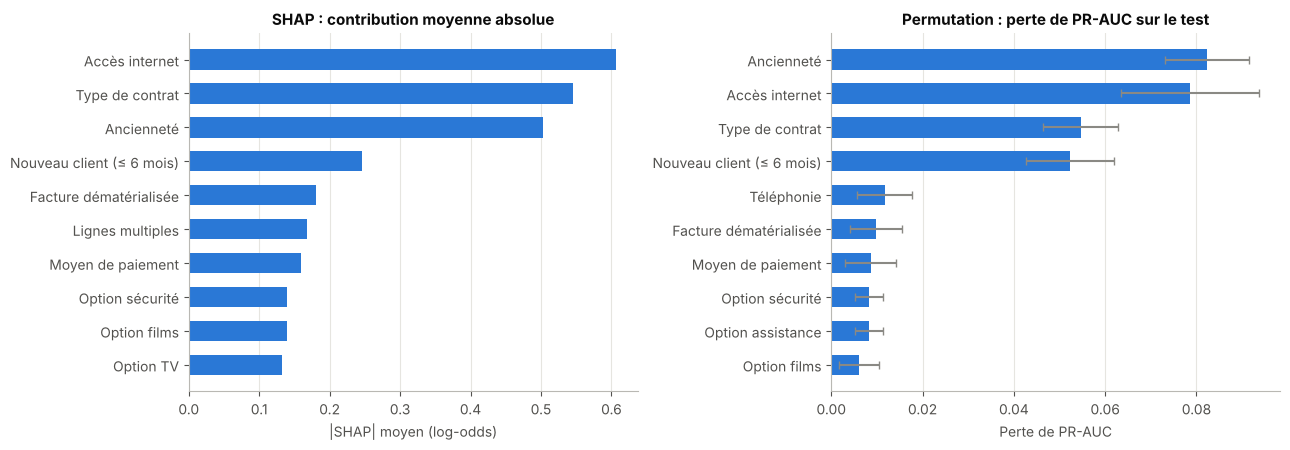

In [38]:
NOMS_FR = {"Contract": "Type de contrat", "tenure": "Ancienneté", "InternetService": "Accès internet",
           "nouveau_client": "Nouveau client (≤ 6 mois)", "PaymentMethod": "Moyen de paiement",
           "OnlineSecurity": "Option sécurité", "TechSupport": "Option assistance", "PaperlessBilling": "Facture dématérialisée",
           "StreamingMovies": "Option films", "StreamingTV": "Option TV", "MultipleLines": "Lignes multiples",
           "SeniorCitizen": "Client senior", "Dependents": "Personnes à charge", "Partner": "En couple",
           "OnlineBackup": "Option sauvegarde", "DeviceProtection": "Option protection", "PhoneService": "Téléphonie"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
top = importance_shap.head(10)[::-1]
axes[0].barh([NOMS_FR.get(v, v) for v in top.index], top.values, color=BLEU, height=0.6)
axes[0].set(title="SHAP : contribution moyenne absolue", xlabel="|SHAP| moyen (log-odds)")
top = importance_perm["perte de PR-AUC"].head(10)[::-1]
axes[1].barh([NOMS_FR.get(v, v) for v in top.index], top.values, color=BLEU, height=0.6,
             xerr=importance_perm["écart-type"].head(10)[::-1], error_kw={"ecolor": GRIS, "capsize": 3})
axes[1].set(title="Permutation : perte de PR-AUC sur le test", xlabel="Perte de PR-AUC")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
sauver(fig, "importance_variables")

Les trois méthodes placent les quatre mêmes variables en tête, dans des ordres un peu différents : l'accès internet, le type de contrat, l'ancienneté et l'indicateur nouveau client. Les deux dernières décrivent la même chose ; on retrouve donc les trois facteurs vus en exploration. Après ce groupe, les contributions chutent nettement.

Les options payantes (lignes multiples, TV, films) ont des coefficients positifs : elles poussent légèrement vers le départ. La facture ayant été retirée du modèle, elles en portent probablement une partie de l'effet prix.

Exemple individuel : le client du test dont le gain espéré est le plus élevé.

tenure                            3
Contract             Month-to-month
InternetService         Fiber optic
PaymentMethod      Electronic check
OnlineSecurity                   No
TechSupport                      No
MonthlyCharges                105.9

Gain espéré d'un contact : 108 $


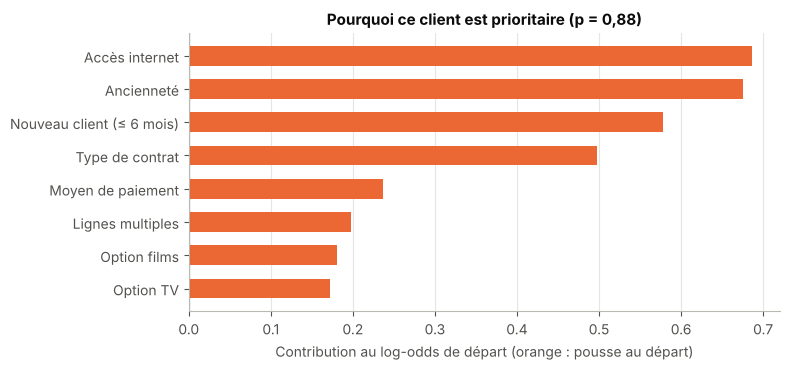

In [39]:
i_client = int(np.argmax(gain_attendu))
contrib = shap_var.iloc[i_client].sort_values(key=np.abs, ascending=False).head(8)[::-1]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([NOMS_FR.get(v, v) for v in contrib.index], contrib.values,
        color=[ORANGE if v > 0 else BLEU for v in contrib.values], height=0.6)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(title=f"Pourquoi ce client est prioritaire (p = {proba_test[i_client]:.2f})".replace(".", ","),
       xlabel="Contribution au log-odds de départ (orange : pousse au départ)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
sauver(fig, "shap_client")

profil = test.iloc[i_client][["tenure", "Contract", "InternetService", "PaymentMethod", "OnlineSecurity",
                              "TechSupport", "MonthlyCharges"]]
print(profil.to_string())
print(f"\nGain espéré d'un contact : {usd(gain_attendu[i_client])}")
R.update(client_anc=int(profil["tenure"]), client_facture=float(profil["MonthlyCharges"]),
         client_proba=float(proba_test[i_client]), client_gain=float(gain_attendu[i_client]),
         client_contrat=LIBELLES["Contract"][profil["Contract"]].lower(),
         client_internet=LIBELLES["InternetService"][profil["InternetService"]].lower(),
         client_paiement=LIBELLES["PaymentMethod"][profil["PaymentMethod"]].lower(),
         client_options=("sans option sécurité ni assistance"
                         if profil["OnlineSecurity"] == "No" and profil["TechSupport"] == "No" else "avec au moins une option"))

Ce client est arrivé il y a 3 mois, sans engagement, en fibre, paie par chèque électronique, sans option sécurité ni assistance. Sa facture est de 105,90 $ et sa probabilité de départ de 0,88. Pour un conseiller, ce graphique résume pourquoi l'appeler en premier.

### 12.3 Modèle explicatif avec intervalles de confiance

Les coefficients pénalisés sont biaisés vers zéro et n'ont pas d'intervalle de confiance. Pour chiffrer les effets, j'estime à part une régression logistique classique (statsmodels) sur un jeu de variables réduit et peu corrélé, avec les clients d'apprentissage. Ce modèle sert à expliquer, pas à prédire.

In [40]:
import statsmodels.formula.api as smf

donnees = train.assign(anciennete_annees=train["tenure"] / 12)
formule = ("Churn ~ C(Contract, Treatment('Month-to-month')) + anciennete_annees + nouveau_client"
           " + C(InternetService, Treatment('DSL')) + C(PaymentMethod, Treatment('Bank transfer (automatic)'))"
           " + PaperlessBilling + OnlineSecurity + TechSupport + SeniorCitizen + Dependents")
logit = smf.logit(formule, data=donnees).fit(disp=False)

LIB = {
    "C(Contract, Treatment('Month-to-month'))[T.One year]": "Contrat 1 an (vs sans engagement)",
    "C(Contract, Treatment('Month-to-month'))[T.Two year]": "Contrat 2 ans (vs sans engagement)",
    "anciennete_annees": "Ancienneté (par année)",
    "nouveau_client": "Nouveau client, ≤ 6 mois",
    "C(InternetService, Treatment('DSL'))[T.Fiber optic]": "Fibre (vs ADSL)",
    "C(InternetService, Treatment('DSL'))[T.No]": "Pas d'internet (vs ADSL)",
    "C(PaymentMethod, Treatment('Bank transfer (automatic)'))[T.Credit card (automatic)]": "Carte auto (vs virement auto)",
    "C(PaymentMethod, Treatment('Bank transfer (automatic)'))[T.Electronic check]": "Chèque électronique (vs virement auto)",
    "C(PaymentMethod, Treatment('Bank transfer (automatic)'))[T.Mailed check]": "Chèque postal (vs virement auto)",
    "PaperlessBilling[T.Yes]": "Facture dématérialisée",
    "OnlineSecurity[T.Yes]": "Option sécurité",
    "TechSupport[T.Yes]": "Option assistance",
    "SeniorCitizen": "Client senior",
    "Dependents[T.Yes]": "Personnes à charge",
}
ic = np.exp(logit.conf_int())
explicatif = pd.DataFrame({"odds ratio": np.exp(logit.params), "IC 95 % bas": ic[0], "IC 95 % haut": ic[1],
                           "p_value": logit.pvalues}).drop(index="Intercept").rename(index=LIB)

for libelle, cle in [("Fibre (vs ADSL)", "fibre"), ("Contrat 2 ans (vs sans engagement)", "2ans"),
                     ("Contrat 1 an (vs sans engagement)", "1an"), ("Chèque électronique (vs virement auto)", "echeck"),
                     ("Ancienneté (par année)", "anc"), ("Nouveau client, ≤ 6 mois", "nouveau"),
                     ("Option sécurité", "secu"), ("Option assistance", "assist"), ("Client senior", "senior"),
                     ("Facture dématérialisée", "dematerialisee")]:
    R[f"or_{cle}"] = float(explicatif.loc[libelle, "odds ratio"])
    R[f"or_{cle}_bas"] = float(explicatif.loc[libelle, "IC 95 % bas"])
    R[f"or_{cle}_haut"] = float(explicatif.loc[libelle, "IC 95 % haut"])
    R[f"p_{cle}"] = float(explicatif.loc[libelle, "p_value"])
R.update(pseudo_r2=float(logit.prsquared), inv_or_2ans=1 / R["or_2ans"], inv_or_1an=1 / R["or_1an"])
print(f"Pseudo-R² de McFadden : {logit.prsquared:.3f} | {int(logit.nobs)} clients")
explicatif.round(3)

Pseudo-R² de McFadden : 0.283 | 5634 clients


,odds ratio,IC 95 % bas,IC 95 % haut,p_value
Contrat 1 an (vs sans engagement),0.513,0.405,0.649,0.000
Contrat 2 ans (vs sans engagement),0.232,0.158,0.341,0.000
Fibre (vs ADSL),2.616,2.200,3.109,0.000
Pas d'internet (vs ADSL),0.341,0.256,0.453,0.000
Carte auto (vs virement auto),0.944,0.736,1.211,0.651
Chèque électronique (vs virement auto),1.505,1.225,1.849,0.000
Chèque postal (vs virement auto),0.997,0.775,1.284,0.983
Facture dématérialisée,1.560,1.325,1.836,0.000
Option sécurité,0.666,0.554,0.800,0.000
Option assistance,0.762,0.633,0.916,0.004


À autres variables égales :

- un engagement de deux ans divise la cote de départ par 4,3 (odds ratio 0,23, IC 95 % : 0,16 à 0,34), un engagement d'un an par 2,0 ;
- la fibre multiplie la cote par 2,62 par rapport à l'ADSL (IC 95 % : 2,20 à 3,11) ;
- être client depuis six mois ou moins la multiplie par 2,01, en plus de l'effet de l'ancienneté (odds ratio de 0,80 par année) ;
- le paiement par chèque électronique la multiplie par 1,51, la facture dématérialisée par 1,56 ;
- les options sécurité (0,67) et assistance (0,76) vont avec moins de départs.

Ce sont des associations, pas des effets causaux. Un client qui choisit un engagement de deux ans avait sans doute déjà l'intention de rester : imposer un engagement ne produirait pas forcément le même effet. De même, souscrire l'option assistance n'empêche pas mécaniquement un départ. Seule une expérimentation peut mesurer l'effet d'une action (section 15).

## 13. Analyse des erreurs

Qui la règle valeur rate-t-elle, et qui contacte-t-elle inutilement ?

In [41]:
contactes = regle_valeur(proba_test, valeur_test)
groupes = np.select(
    [contactes & (y_test == 1), contactes & (y_test == 0), ~contactes & (y_test == 1)],
    ["Contacté, partait", "Contacté, serait resté", "Non contacté, est parti"], "Non contacté, est resté")
profils = test.assign(groupe=groupes, proba=proba_test,
                      sans_engagement=(test["Contract"] == "Month-to-month").astype(int)).groupby("groupe").agg(
    clients=("customerID", "size"), anciennete=("tenure", "mean"), facture=("MonthlyCharges", "mean"),
    sans_engagement=("sans_engagement", "mean"), proba_moyenne=("proba", "mean"))

manques = ~contactes & (y_test == 1)
non_rentables = manques & (TAUX_RETENTION * valeur_test < COUT_OFFRE)
sous_estimes = manques & (proba_test < 0.3)
print(f"Partants non contactés : {manques.sum()}")
print(f"  dont facture trop faible pour qu'un contact soit rentable même à coup sûr : {non_rentables.sum()}")
print(f"  dont risque estimé sous 30 %                                         : {sous_estimes.sum()}\n")
R.update(fn_valeur=int(manques.sum()), fn_non_rentables=int(non_rentables.sum()), fn_sous_estimes=int(sous_estimes.sum()),
         fp_valeur=int((contactes & (y_test == 0)).sum()),
         anc_fn=float(profils.loc["Non contacté, est parti", "anciennete"]),
         anc_tp=float(profils.loc["Contacté, partait", "anciennete"]),
         eng_fn=1 - float(profils.loc["Non contacté, est parti", "sans_engagement"]),
         eng_tp=1 - float(profils.loc["Contacté, partait", "sans_engagement"]),
         proba_fp=float(profils.loc["Contacté, serait resté", "proba_moyenne"]),
         proba_tp=float(profils.loc["Contacté, partait", "proba_moyenne"]))
profils

Partants non contactés : 162
  dont facture trop faible pour qu'un contact soit rentable même à coup sûr : 39
  dont risque estimé sous 30 %                                         : 89



,clients,anciennete,facture,sans_engagement,proba_moyenne
groupe,,,,,
"Contacté, partait",212,13.090,85.200,0.986,0.646
"Contacté, serait resté",151,20.907,88.339,0.954,0.557
"Non contacté, est parti",162,20.877,56.496,0.741,0.299
"Non contacté, est resté",884,40.334,56.275,0.339,0.123


Sur les 162 partants non contactés, 39 ont une facture trop faible pour que l'offre soit rentable : ce n'est pas une erreur du modèle mais une limite de l'offre. 89 avaient un risque estimé sous 30 %. Ces partants manqués sont plus anciens que les partants bien repérés (21 mois en moyenne contre 13) et plus souvent engagés (26 % contre 1 %). Rien dans les données n'annonce leur départ : un déménagement, une offre concurrente ou un incident de service n'y figurent pas.

Les 151 clients contactés sans nécessité ressemblent beaucoup aux vrais partants : sans engagement, facture élevée, probabilité moyenne de 0,56 contre 0,65. Avec les variables disponibles, ils sont difficiles à distinguer.

### 13.1 Performance par segment

In [42]:
rng = np.random.default_rng(RANDOM_STATE)
lignes = []
for col in ["Contract", "InternetService", "SeniorCitizen"]:
    for modalite in sorted(test[col].unique()):
        m = (test[col] == modalite).to_numpy()
        y_s, p_s = y_test[m], proba_test[m]
        aucs = []
        for _ in range(500):
            i = rng.integers(0, m.sum(), m.sum())
            if 0 < y_s[i].sum() < len(i):
                aucs.append(roc_auc_score(y_s[i], p_s[i]))
        lignes.append({"variable": col, "segment": modalite, "clients": int(m.sum()), "partants": int(y_s.sum()),
                       "ROC-AUC": roc_auc_score(y_s, p_s), "IC 95 % bas": np.percentile(aucs, 2.5),
                       "IC 95 % haut": np.percentile(aucs, 97.5),
                       "proba moyenne": p_s.mean(), "taux observé": y_s.mean()})
perf_segments = pd.DataFrame(lignes)
R["partants_2ans_test"] = int(perf_segments.query("segment == 'Two year'")["partants"].iloc[0])
R["auc_seg_min"] = float(perf_segments["ROC-AUC"].min())
R["auc_seg_max"] = float(perf_segments["ROC-AUC"].max())
R["ecart_calib_seg_max"] = float((perf_segments["proba moyenne"] - perf_segments["taux observé"]).abs().max())
R["ecart_calib_seg_max_pts"] = 100 * R["ecart_calib_seg_max"]
perf_segments.round(3)

,variable,segment,clients,partants,ROC-AUC,IC 95 % bas,IC 95 % haut,proba moyenne,taux observé
0,Contract,Month-to-month,773,329,0.752,0.721,0.782,0.430,0.426
1,Contract,One year,300,36,0.750,0.678,0.822,0.118,0.120
2,Contract,Two year,336,9,0.736,0.496,0.898,0.032,0.027
3,InternetService,DSL,484,97,0.828,0.783,0.872,0.186,0.200
4,InternetService,Fiber optic,613,252,0.786,0.749,0.824,0.431,0.411
5,InternetService,No,312,25,0.891,0.848,0.930,0.078,0.080
6,SeniorCitizen,0,1187,276,0.847,0.826,0.873,0.241,0.233
7,SeniorCitizen,1,222,98,0.785,0.719,0.843,0.417,0.441


La ROC-AUC varie d'un segment à l'autre (0,74 à 0,89), mais les intervalles de confiance sont larges dès que le segment compte peu de partants : le segment engagement deux ans n'en a que 9 dans le test, son score n'est pas interprétable. Plus important pour l'usage métier, la probabilité moyenne prédite reste proche du taux observé dans chaque segment (écart maximal de 2,5 points) : le modèle ne surestime ni ne sous-estime systématiquement un groupe.

## 14. Robustesse

Gain de PR-AUC en validation entre 2189 et 4507 clients : +0.0018
Écart final apprentissage − validation : 0.0048


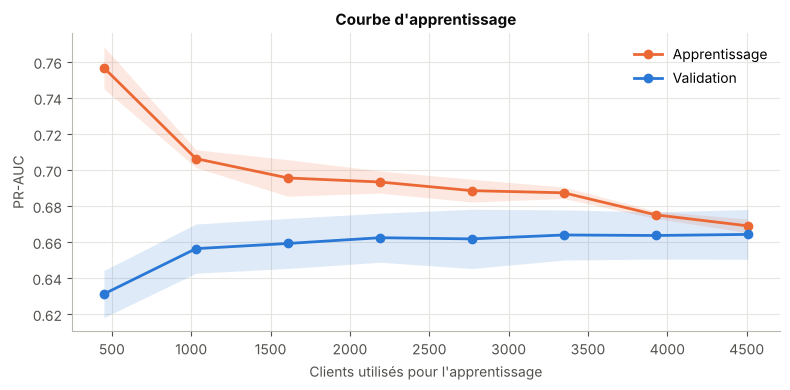

In [43]:
from sklearn.model_selection import learning_curve

tailles, sc_train, sc_valid = learning_curve(
    modele_final, X_train, y_train, cv=cv5, scoring="average_precision",
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)

fig, ax = plt.subplots(figsize=(8, 4))
for sc, nom, couleur in [(sc_train, "Apprentissage", ORANGE), (sc_valid, "Validation", BLEU)]:
    ax.plot(tailles, sc.mean(axis=1), marker="o", lw=2, color=couleur, label=nom)
    ax.fill_between(tailles, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=couleur, alpha=0.15, linewidth=0)
ax.set(title="Courbe d'apprentissage", xlabel="Clients utilisés pour l'apprentissage", ylabel="PR-AUC")
ax.legend()
plt.tight_layout()
sauver(fig, "courbe_apprentissage")

R.update(lc_gain_derniere_moitie=float(sc_valid.mean(1)[-1] - sc_valid.mean(1)[3]),
         lc_ecart_final=float(sc_train.mean(1)[-1] - sc_valid.mean(1)[-1]))
print(f"Gain de PR-AUC en validation entre {tailles[3]} et {tailles[-1]} clients : {R['lc_gain_derniere_moitie']:+.4f}")
print(f"Écart final apprentissage − validation : {R['lc_ecart_final']:.4f}")

Les scores d'apprentissage et de validation sont proches (écart final de 0,005) : le modèle ne sur-apprend pas. Et doubler le nombre de clients d'apprentissage n'améliore presque pas la validation (+0,002). Collecter plus de lignes du même type ne servirait à rien ; pour progresser, il faudrait d'autres informations : réclamations, incidents réseau, usage du service, contacts avec le support.

## 15. Plan de test A/B

Le taux de rétention de l'offre décide de la rentabilité, et aucun modèle prédictif ne peut l'estimer : il faut l'expérimenter. Je propose de tirer au sort, parmi les clients sélectionnés par la règle valeur, un groupe contacté et un groupe témoin non contacté, puis de comparer leurs taux de départ. Le tableau donne la taille nécessaire par groupe (risque α de 5 %, puissance de 80 %), à partir du taux de départ observé chez les clients ciblés du test (58,4 %).

In [44]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

depart_cible = y_test[regle_valeur(proba_test, valeur_test)].mean()
puissance = NormalIndPower()
lignes = []
for retention in [0.10, 0.20, 0.30]:
    depart_traite = depart_cible * (1 - retention)
    taille = puissance.solve_power(effect_size=proportion_effectsize(depart_cible, depart_traite),
                                   alpha=0.05, power=0.8, ratio=1.0)
    lignes.append({"taux de rétention à détecter": pct(retention, 0),
                   "départ groupe témoin": pct(depart_cible), "départ groupe contacté": pct(depart_traite),
                   "clients par groupe": int(np.ceil(taille))})
plan_ab = pd.DataFrame(lignes).set_index("taux de rétention à détecter")
R["depart_cible"] = float(depart_cible)
R["ab_n_10"] = int(plan_ab["clients par groupe"].iloc[0])
R["ab_n_20"] = int(plan_ab["clients par groupe"].iloc[1])
R["ab_n_30"] = int(plan_ab["clients par groupe"].iloc[2])
plan_ab

,départ groupe témoin,départ groupe contacté,clients par groupe
taux de rétention à détecter,,,
10 %,"58,4 %","52,6 %",1136
20 %,"58,4 %","46,7 %",286
30 %,"58,4 %","40,9 %",127


Pour détecter un taux de rétention de 20 %, proche du seuil de rentabilité, il faut 286 clients par groupe. La règle valeur sélectionne 1 778 clients dans toute la base : le test tient en une seule vague. Pour détecter un effet de 10 %, il en faudrait 1 136 par groupe. Les résultats permettraient ensuite d'estimer un modèle d'uplift, qui cible les clients que l'offre fait réellement rester plutôt que ceux qui vont partir.

## 16. Conclusions

### Recommandations

| Priorité | Action | Appui |
|---|---|---|
| 1 | Tester l'offre par A/B (286 clients par groupe) avant tout déploiement | la campagne perd de l'argent sous 20 % de rétention (10.3) |
| 2 | Contacter selon la règle valeur, en commençant par le segment risque élevé et facture élevée | 50 % de la facturation à risque pour 17 % des clients (11) |
| 3 | Concentrer l'effort sur les six premiers mois et proposer un contrat engageant | 53 % de départs dans les six premiers mois (3.3) |
| 4 | Ouvrir une analyse de la fibre avec l'équipe produit : prix, qualité du réseau | cote de départ multipliée par 2,6 par rapport à l'ADSL, à profil égal (12.3) |
| 5 | Prévoir une action moins coûteuse pour les clients à petite facture | l'offre n'est jamais rentable sous 33,33 $ par mois (1) |

### Limites

- **Pas de causalité.** Le modèle prédit qui part, pas l'effet d'une action. Le type de contrat reflète sans doute l'intention initiale du client autant qu'il la façonne.
- **Hypothèses économiques non mesurées.** Le résultat dépend surtout du taux de rétention, que seul un test peut établir.
- **Une seule photographie de la base.** Les clients partis avant l'extraction ne sont pas dans le fichier, ce qui fausserait une analyse de survie : je ne modélise donc pas le temps jusqu'au départ.
- **Jeu en partie synthétique.** Taux de départ élevé, facture issue d'une grille exacte. La méthode se transpose ; les chiffres, non.

### Suites

1. Exploiter le test A/B pour estimer un modèle d'uplift.
2. Avec un historique mensuel, modéliser le temps jusqu'au départ (Kaplan-Meier, modèle de Cox) pour savoir quand intervenir.
3. Ajouter les réclamations, la qualité de service et l'usage.
4. En production, suivre chaque mois la dérive des variables et la calibration du modèle.

In [45]:
def en_json(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    return v


(RES / "metriques.json").write_text(
    json.dumps({k: en_json(v) for k, v in R.items()}, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"{len(R)} indicateurs enregistrés dans resultats/metriques.json")

250 indicateurs enregistrés dans resultats/metriques.json
